In [2]:
import sys
sys.path.append('/home/thies/repos/BIU/')
import biu
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
plt.rcParams['svg.fonttype'] = 'none'

import seaborn as sns
import scipy


In [3]:
Q = pd.read_csv('../data/GMO questionnaire_October 30, 2024_12.41.csv')
list(Q.iloc[0])

['Start Date',
 'End Date',
 'Response Type',
 'IP Address',
 'Progress',
 'Duration (in seconds)',
 'Finished',
 'Recorded Date',
 'Response ID',
 'Recipient Last Name',
 'Recipient First Name',
 'Recipient Email',
 'External Data Reference',
 'Location Latitude',
 'Location Longitude',
 'Distribution Channel',
 'User Language',
 "Welcome!     \n\n\n\nWe are researchers interested in how the general public thinks about techniques to modify the functionalities of microorganisms. In the first part of this survey, we will introduce the concept of microbial factories, after which we will ask you different questions to gain insights into how you feel about their use. After that, we will present different applications of microbial factories and ask different questions to get insights into your needs, concerns, and beliefs about these specific applications. Your input will help us align our work as researchers developing microbial factories with practical needs and societal impact.\n\n\n\nYo


# Analysis plan 

## Compare each question response between all domains (pairwise) 

 * Ordinal logistic regression 

## Compare all questions within a single domain 

 * Ordinal logistic regression  

 * Take average within each category of question 

 

# Load data

In [4]:
Q = pd.read_csv('../data/GMO questionnaire_October 30, 2024_12.41.csv')
Q.columns = [ c.lower() for c in Q.columns ]
Q = Q.set_index('prolific_pid')
Q = Q.rename(columns={
    'q69_1': 'art_dangerous_1',
    'q69_2': 'art_dangerous_2',
    'q69_3': 'art_dangerous_3'
})

groups = ['vaccines','environ', 'food', 'art']

group_questions = [
    'useful_1', 'useful_2', 'useful_3', 
    'dangerous_1', 'dangerous_2', 'dangerous_3'
]

question_names = dict( zip(Q.columns, Q.iloc[0]) )

all_questions = [ '%s_%s' % (g,q) for g in groups for q in group_questions ]

Q = Q.iloc[2:]

## Transform lichert scores to numerical values

In [5]:
lichert_questions = [
       'microfact_feelings_1', 'microfact_feelings_2', 'microfact_feelings_3',
       'microfact_feelings_4', 'microfact_feelings_5',
       'vaccines_useful_1', 'vaccines_useful_2', 'vaccines_useful_3',
       'vaccines_dangerous_1', 'vaccines_dangerous_2', 'vaccines_dangerous_3',
        'environ_useful_1',
       'environ_useful_2', 'environ_useful_3', 'environ_dangerous_1',
       'environ_dangerous_2', 'environ_dangerous_3',
       'food_useful_1', 'food_useful_2', 'food_useful_3',
       'food_dangerous_1', 'food_dangerous_2', 'food_dangerous_3',
       'art_useful_1', 'art_useful_2',
       'art_useful_3', 'art_dangerous_1', 'art_dangerous_2', 'art_dangerous_3']

In [6]:
def transform_lichert(value):
    if pd.isna(value):
        return None
    #fi
    lookup = {
        
        'Neutral': 0,
        
        'Safe': 0.5,
        'Agree': 0.5,
        'Useful': 0.5,
        
        'Strongly agree': 1,
        'Very safe': 1,
        'Very useful': 1,
        
        'Disagree': -0.5,
        'Dangerous': -0.5,
        'Not useful': -0.5,

        'Strongly disagree': -1,
        'Not useful at all': -1,
        'Very dangerous': -1}
    if value not in lookup:
        print(value)
        return None
    #fi
    
    return lookup[value]
#edef

In [7]:
QC = Q[[]].copy()
for g in groups:
    for q in group_questions:
        qid = '%s_%s' % (g, q)
        QC[qid] = Q[qid].apply(transform_lichert).copy()
    #efor
#efor

## Add additional information about pre-existing knowledge

In [8]:
for g in groups:
    qid = '%s_knowledge' % g
    QC[qid] = Q[qid].apply(lambda x: None if pd.isna(x) else x == 'Yes')
#efor

## Add participant metadata

In [9]:
D = pd.read_csv('../data/prolific_export_demographic.csv').set_index('Participant id')
D = D.rename(columns={
    'Age' : 'age',
    'Sex' : 'sex',
    'Ethnicity simplified' : 'ethnicity',
    'Country of birth' : 'birthcountry',
    'Country of residence' : 'residence',
    'Nationality' : 'nationality'
})
D = D[D.age != 'CONSENT_REVOKED']
D['age'] = D['age'].astype(int)
QC = QC.loc[list(set(D.index) & set(QC.index))].join(D[['age', 'sex', 'ethnicity', 'birthcountry', 'residence', 'nationality']])

## Duplicates & missing values?

### Remove those with totally missing values

In [10]:
empty = QC.index[QC.isna().sum(axis=1) == 28]

print("Removing the following because of differing responses in duplicate IDs", empty)

QC = QC.drop(index=empty)

Removing the following because of differing responses in duplicate IDs Index(['63d7a324bd2bbe98bdb8806e', '6716c7648e0a111ea1ddc255',
       '66d5fff4c366d965c27e7940', '5dda787ac944d19d99bdcfdf'],
      dtype='object', name='prolific_pid')


### Remove Duplicates

In [11]:
duplicates = biu.ops.lst.qerf(QC.index)
duplicate_keys = [ k for k in duplicates.keys() if k > 1 ]
duplicates = biu.ops.lst.flatten([ duplicates[k] for k in duplicate_keys])

to_remove = []

for dup in duplicates:
    if QC.loc[duplicates].drop_duplicates().shape[0] != 1:
        to_remove.append(dup)
    #fi
#efor

print("Removing the following because of differing responses in duplicate IDs", to_remove)

QC = QC.drop(index=to_remove)

Removing the following because of differing responses in duplicate IDs ['665d56116ed34ec4be8da4f2']


## Export data

In [14]:

QC.to_csv("../results/questionnaire_responses.csv", index=False)

# Plot

## Plotting functions

In [248]:


def move_colorbar(ax, data, width="5%", height="100%", loc='lower left', cmap='plasma', center=None):

    if center is None:
        norm = plt.Normalize(data.min(), data.max())
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    else:
        import matplotlib
        vmin, vmax = data.min(), data.max()
        norm = matplotlib.colors.CenteredNorm()
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_clim(vmin, vmax)
    #fi

    if ax.get_legend() is not None:
        ax.get_legend().remove()
    #fi
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    axins = inset_axes(ax,
           width=width,  # width = 5% of parent_bbox width
           height=height,  # height : 50%
           loc=loc,
           bbox_to_anchor=(1.05, 0., 1, 1),
           bbox_transform=ax.transAxes,
           borderpad=0,
           )
    ax.figure.colorbar(sm, cax=axins)
#edef

## Colormaps

In [230]:
palette_questions = ["#b35806", "#f1a340", "#fee0b6", "#542788", "#998ec3", "#d8daeb"]
cmap_questions = lambda i : palette_questions[i%6]

palette_groups = ["#ca0020", "#f4a582", "#0571b0", "#92c5de"]
cmap_groups = lambda i : palette_groups[i%4]

## Plots

In [75]:
QC.reset_index(names="index")

,index,vaccines_useful_1,vaccines_useful_2,vaccines_useful_3,vaccines_dangerous_1,vaccines_dangerous_2,vaccines_dangerous_3,environ_useful_1,environ_useful_2,environ_useful_3,...,vaccines_knowledge,environ_knowledge,food_knowledge,art_knowledge,age,sex,ethnicity,birthcountry,residence,nationality
0,666adfb904eb295a20257f8e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,False,True,34,Female,White,United Kingdom,United Kingdom,United Kingdom
1,6649fa3addad08c7fd3cdef9,0.0,0.5,-0.5,0.5,0.0,0.5,0.5,-1.0,0.5,...,False,True,True,True,29,Female,Black,Kenya,Canada,Kenya
2,62b6eacb30532251b7eb05c1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,False,False,False,False,55,Female,White,United Kingdom,United Kingdom,United Kingdom
3,5bc744dcedc59100010c9de5,0.0,1.0,1.0,0.5,0.5,0.5,1.0,0.5,0.5,...,False,True,False,False,54,Male,White,United Kingdom,United Kingdom,United Kingdom
4,66b3881f8097ad407985d14e,0.5,0.5,0.5,0.0,0.0,0.0,0.5,0.5,0.5,...,False,False,False,False,52,Male,White,Ireland,Ireland,Ireland
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,6707f0be4e5cedfadea1fb92,0.5,1.0,0.5,0.0,0.5,0.5,1.0,0.5,0.5,...,True,True,True,False,57,Male,White,Canada,Canada,Canada
489,6715fa8490b20c9f0317e48d,0.0,0.5,0.0,0.5,0.0,0.0,0.5,0.0,0.0,...,True,False,False,True,58,Male,Mixed,United Kingdom,United Kingdom,United Kingdom
490,657e12e268c10e5855c115f9,0.0,1.0,0.5,0.0,0.5,0.0,1.0,0.5,1.0,...,False,False,False,False,28,Female,White,Canada,Canada,Canada
491,5f7f07d317a72e01b1c57f27,1.0,1.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0,...,False,False,False,False,29,Female,Black,South Africa,South Africa,South Africa


<Axes: xlabel='question', ylabel='value'>

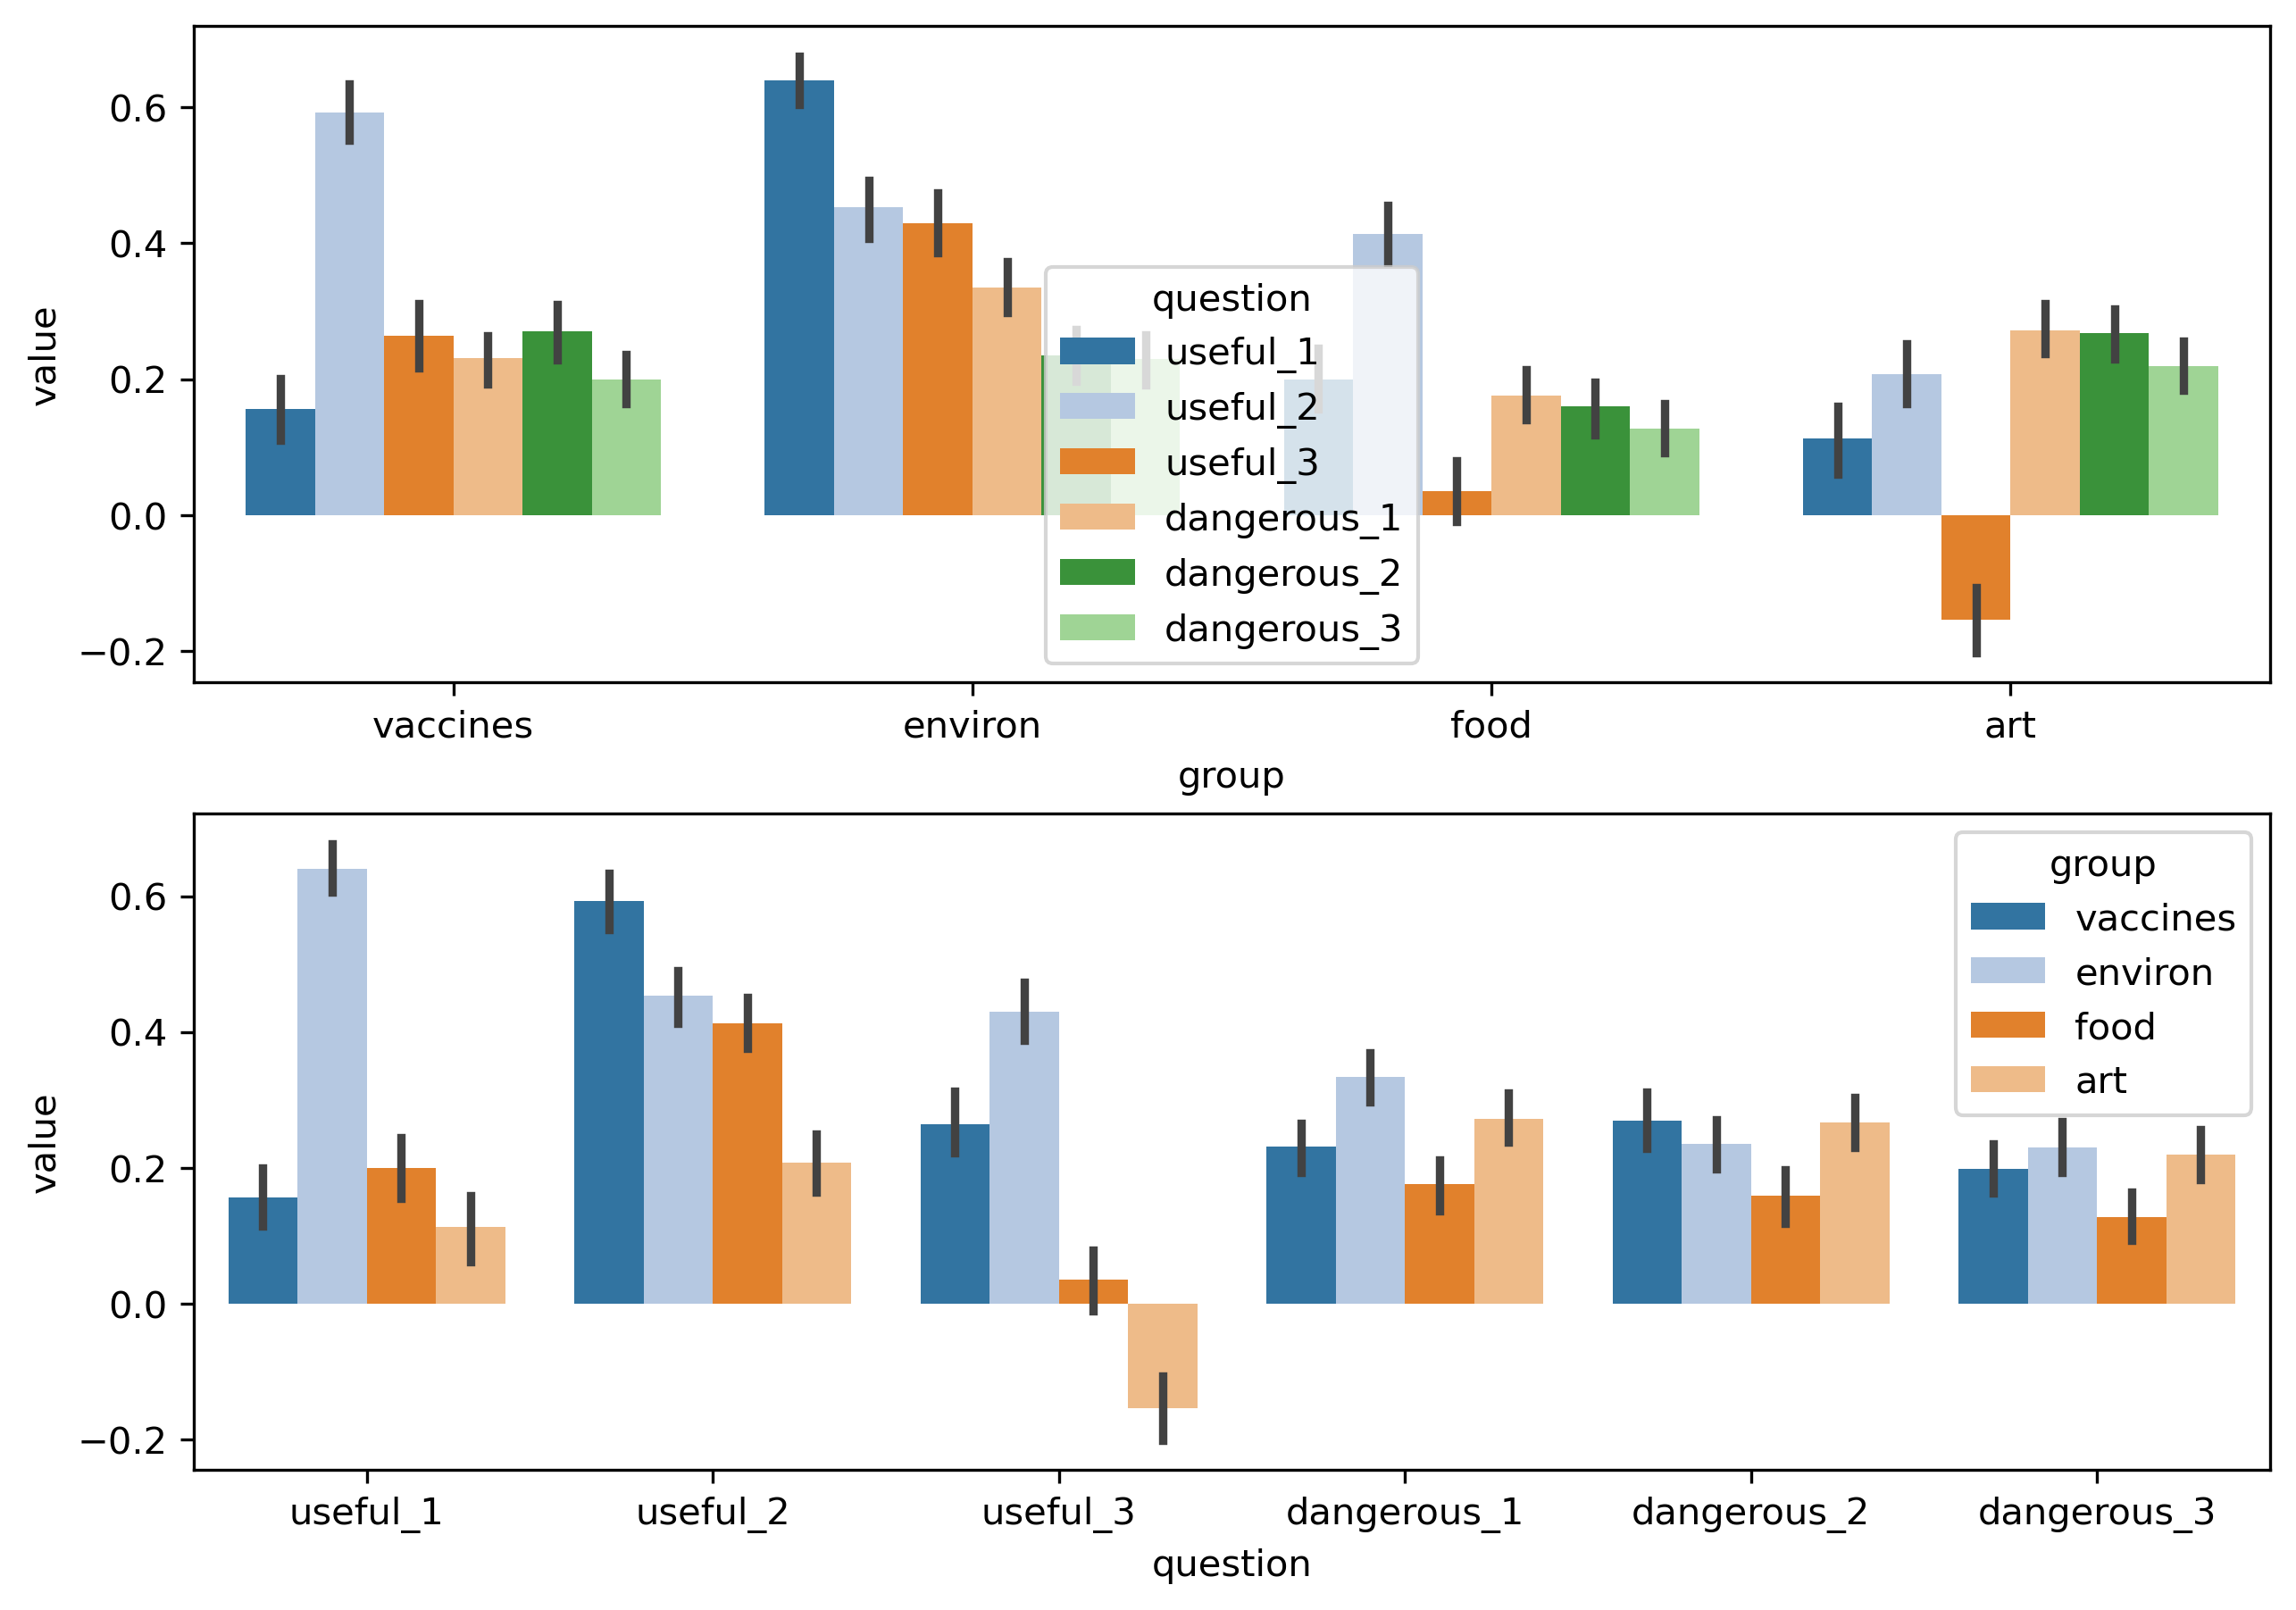

In [76]:
QC_melt = QC.reset_index(names="index").melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))

#sns.barplot(x='group', y='value', hue='question', data=QC_melt)

fig, axes = biu.utils.figure.subplots(figsize=(10,7), nrows=2)
sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[0], palette='tab20')

sns.barplot(x='question', y='value', hue='group', data=QC_melt, ax=axes[1], palette='tab20')

# Construct formulas

In [77]:
formulas = {}

for g_i in range(len(groups)):
    for g_j in range(len(groups)):
        if g_j < g_i:
            continue
        #fi
        
        for q_i in range(len(group_questions)):
            for q_j in range(len(group_questions)):
                if q_j < q_i:
                    continue
                elif (g_j != g_i) & (q_i != q_j):
                    continue
                #elif (g_i == g_j) & (q_i == q_j):
                #    continue
                #fi

                X = '%s_%s' % (groups[g_i], group_questions[q_i])
                Y = '%s_%s' % (groups[g_j], group_questions[q_j])
                Z = [ '%s_knowledge' % (groups[g_i]),
                      'age', 'sex', 'residence' ]
                
                if g_i != g_j:
                    Z.append('%s_knowledge' % (groups[g_j]))
                #fi
                
                
                formulas[X, Y] = Z

            #efor
        #efor
    #efor
#efor               

# Perform linear regression differential scoring analysis

In [249]:
res_ds = []
for (X, Y), Z in formulas.items():

    if X == Y:
        continue
    #fi

    print("\r %s, %s            " % (X, Y), end="")


    side1 = QC[[X]+Z].rename(columns={X:"variable"})
    side1['side'] = False
    
    side2 = QC[[Y]+Z].rename(columns={Y:"variable"})
    side2['side'] = True
    
    data = pd.concat([side1, side2])
    data['participant'] = data.index
    data = data.reset_index(drop=True)
    
    formula = "variable ~ %s" % (' + '.join(["side", "(1|participant)"] + Z))
    
    R("""
    library(lmerTest)
    
    fit <- lmer(as.formula(formula), data=data)
    
    coef <- as.data.frame(coefficients(summary(fit)))
    
    NULL
    """, push=dict(formula=formula, data=data))
    
    r = R("coef")
    r['lhs'] = X
    r['rhs'] = Y
    r['lhs_group'] = X.split('_')[0]
    r['rhs_group'] = Y.split('_')[0]
    r['lhs_question'] = '_'.join(X.split('_')[1:])
    r['rhs_question'] = '_'.join(Y.split('_')[1:])

    res_ds.append(r.loc[['sideTRUE']])

#efor

res_ds = pd.concat(res_ds).reset_index(drop=True)
res_ds['qvalue'] = biu.stats.p_adjust(res_ds['Pr(>|t|)'])

 art_dangerous_2, art_dangerous_3                      

## Visualise

In [250]:
res = res_ds

### Intragroup questions

/tmp/ipykernel_3628891/3432244078.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3432244078.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3432244078.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3432244078.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


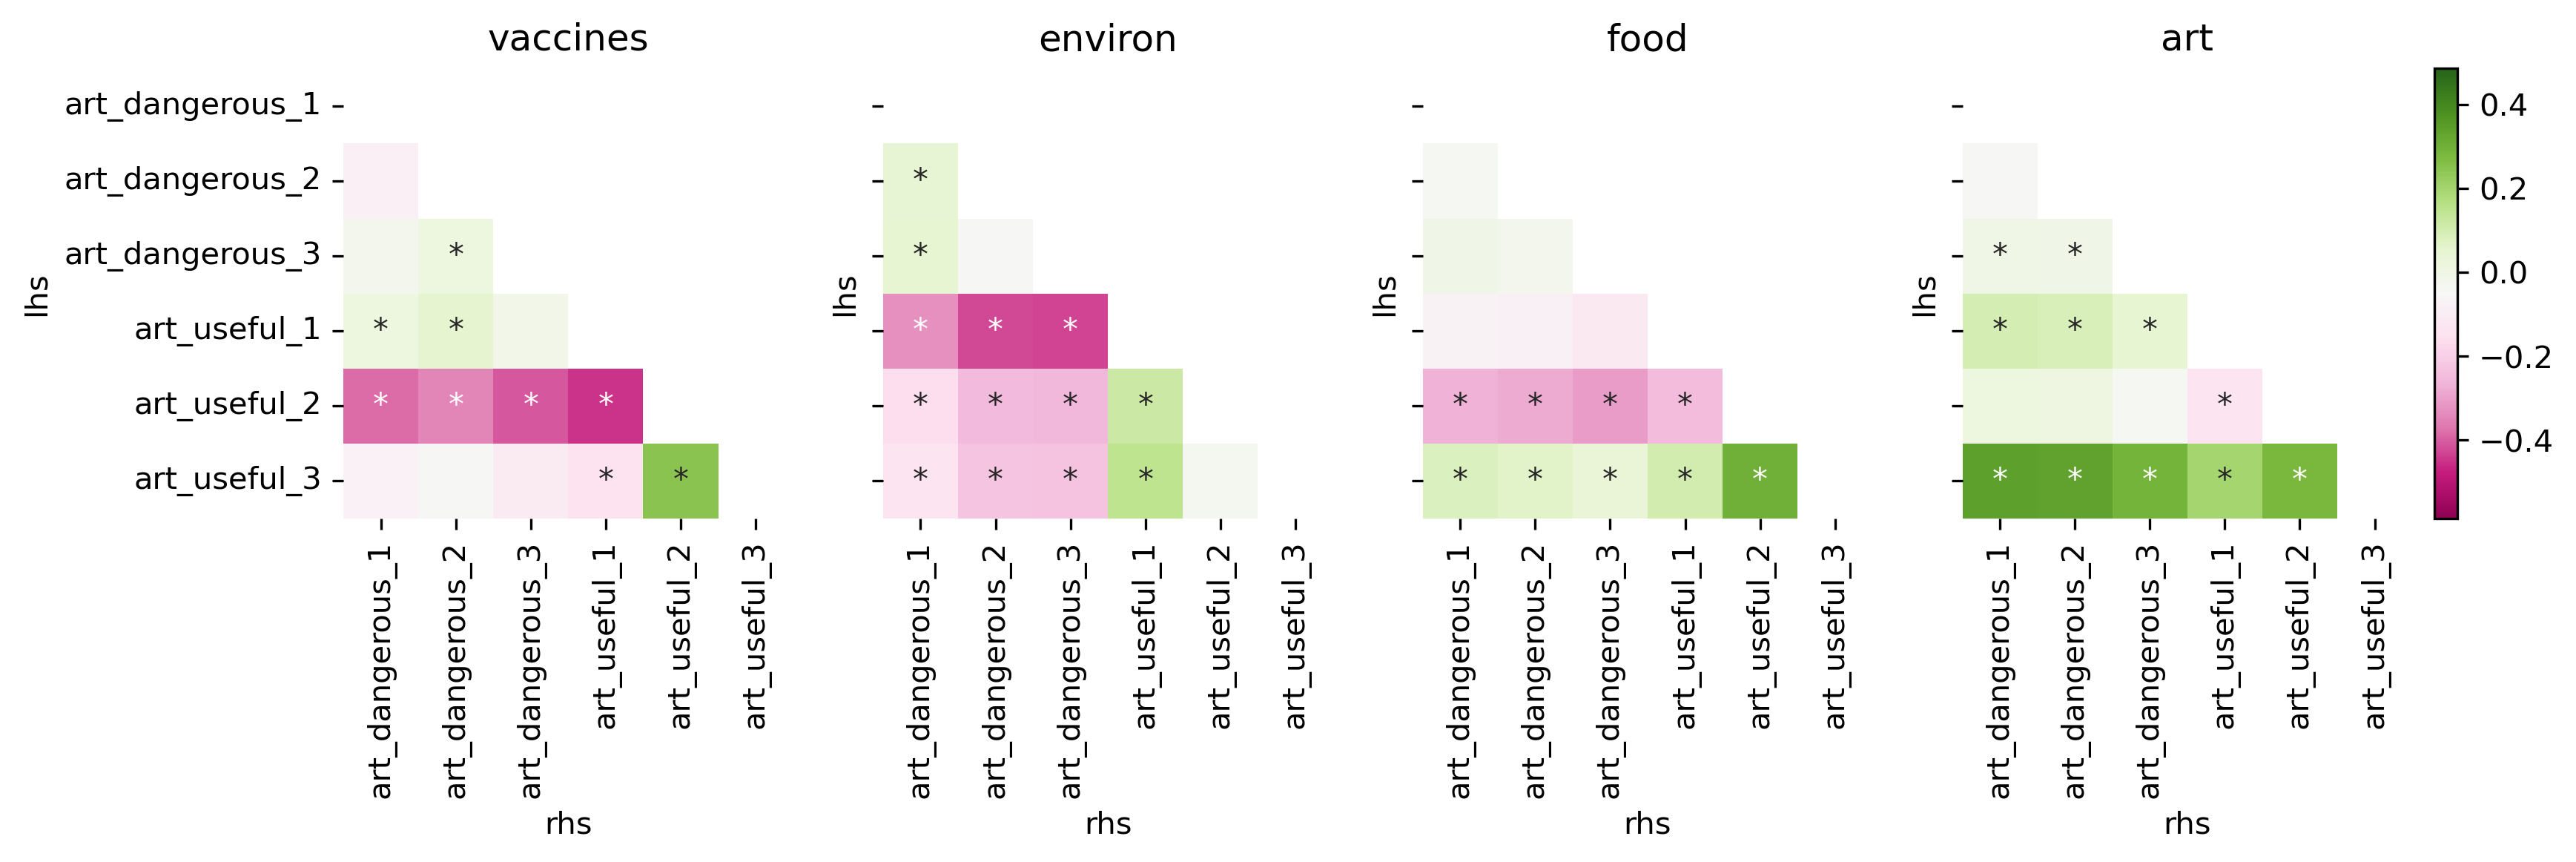

In [251]:
fig, axes = biu.utils.figure.subplots(figsize=(12,3), ncols=4, sharex=True, sharey=True)

for i, g in enumerate(groups):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    rprim.Estimate = -rprim.Estimate
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='Estimate')
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue')
    #upper_tri = 
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=min(res.Estimate), vmax=max(res.Estimate), center=0, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
#efor

move_colorbar(axes[-1], res.Estimate, cmap="PiYG")

/tmp/ipykernel_3628891/2469903356.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2469903356.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2469903356.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2469903356.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


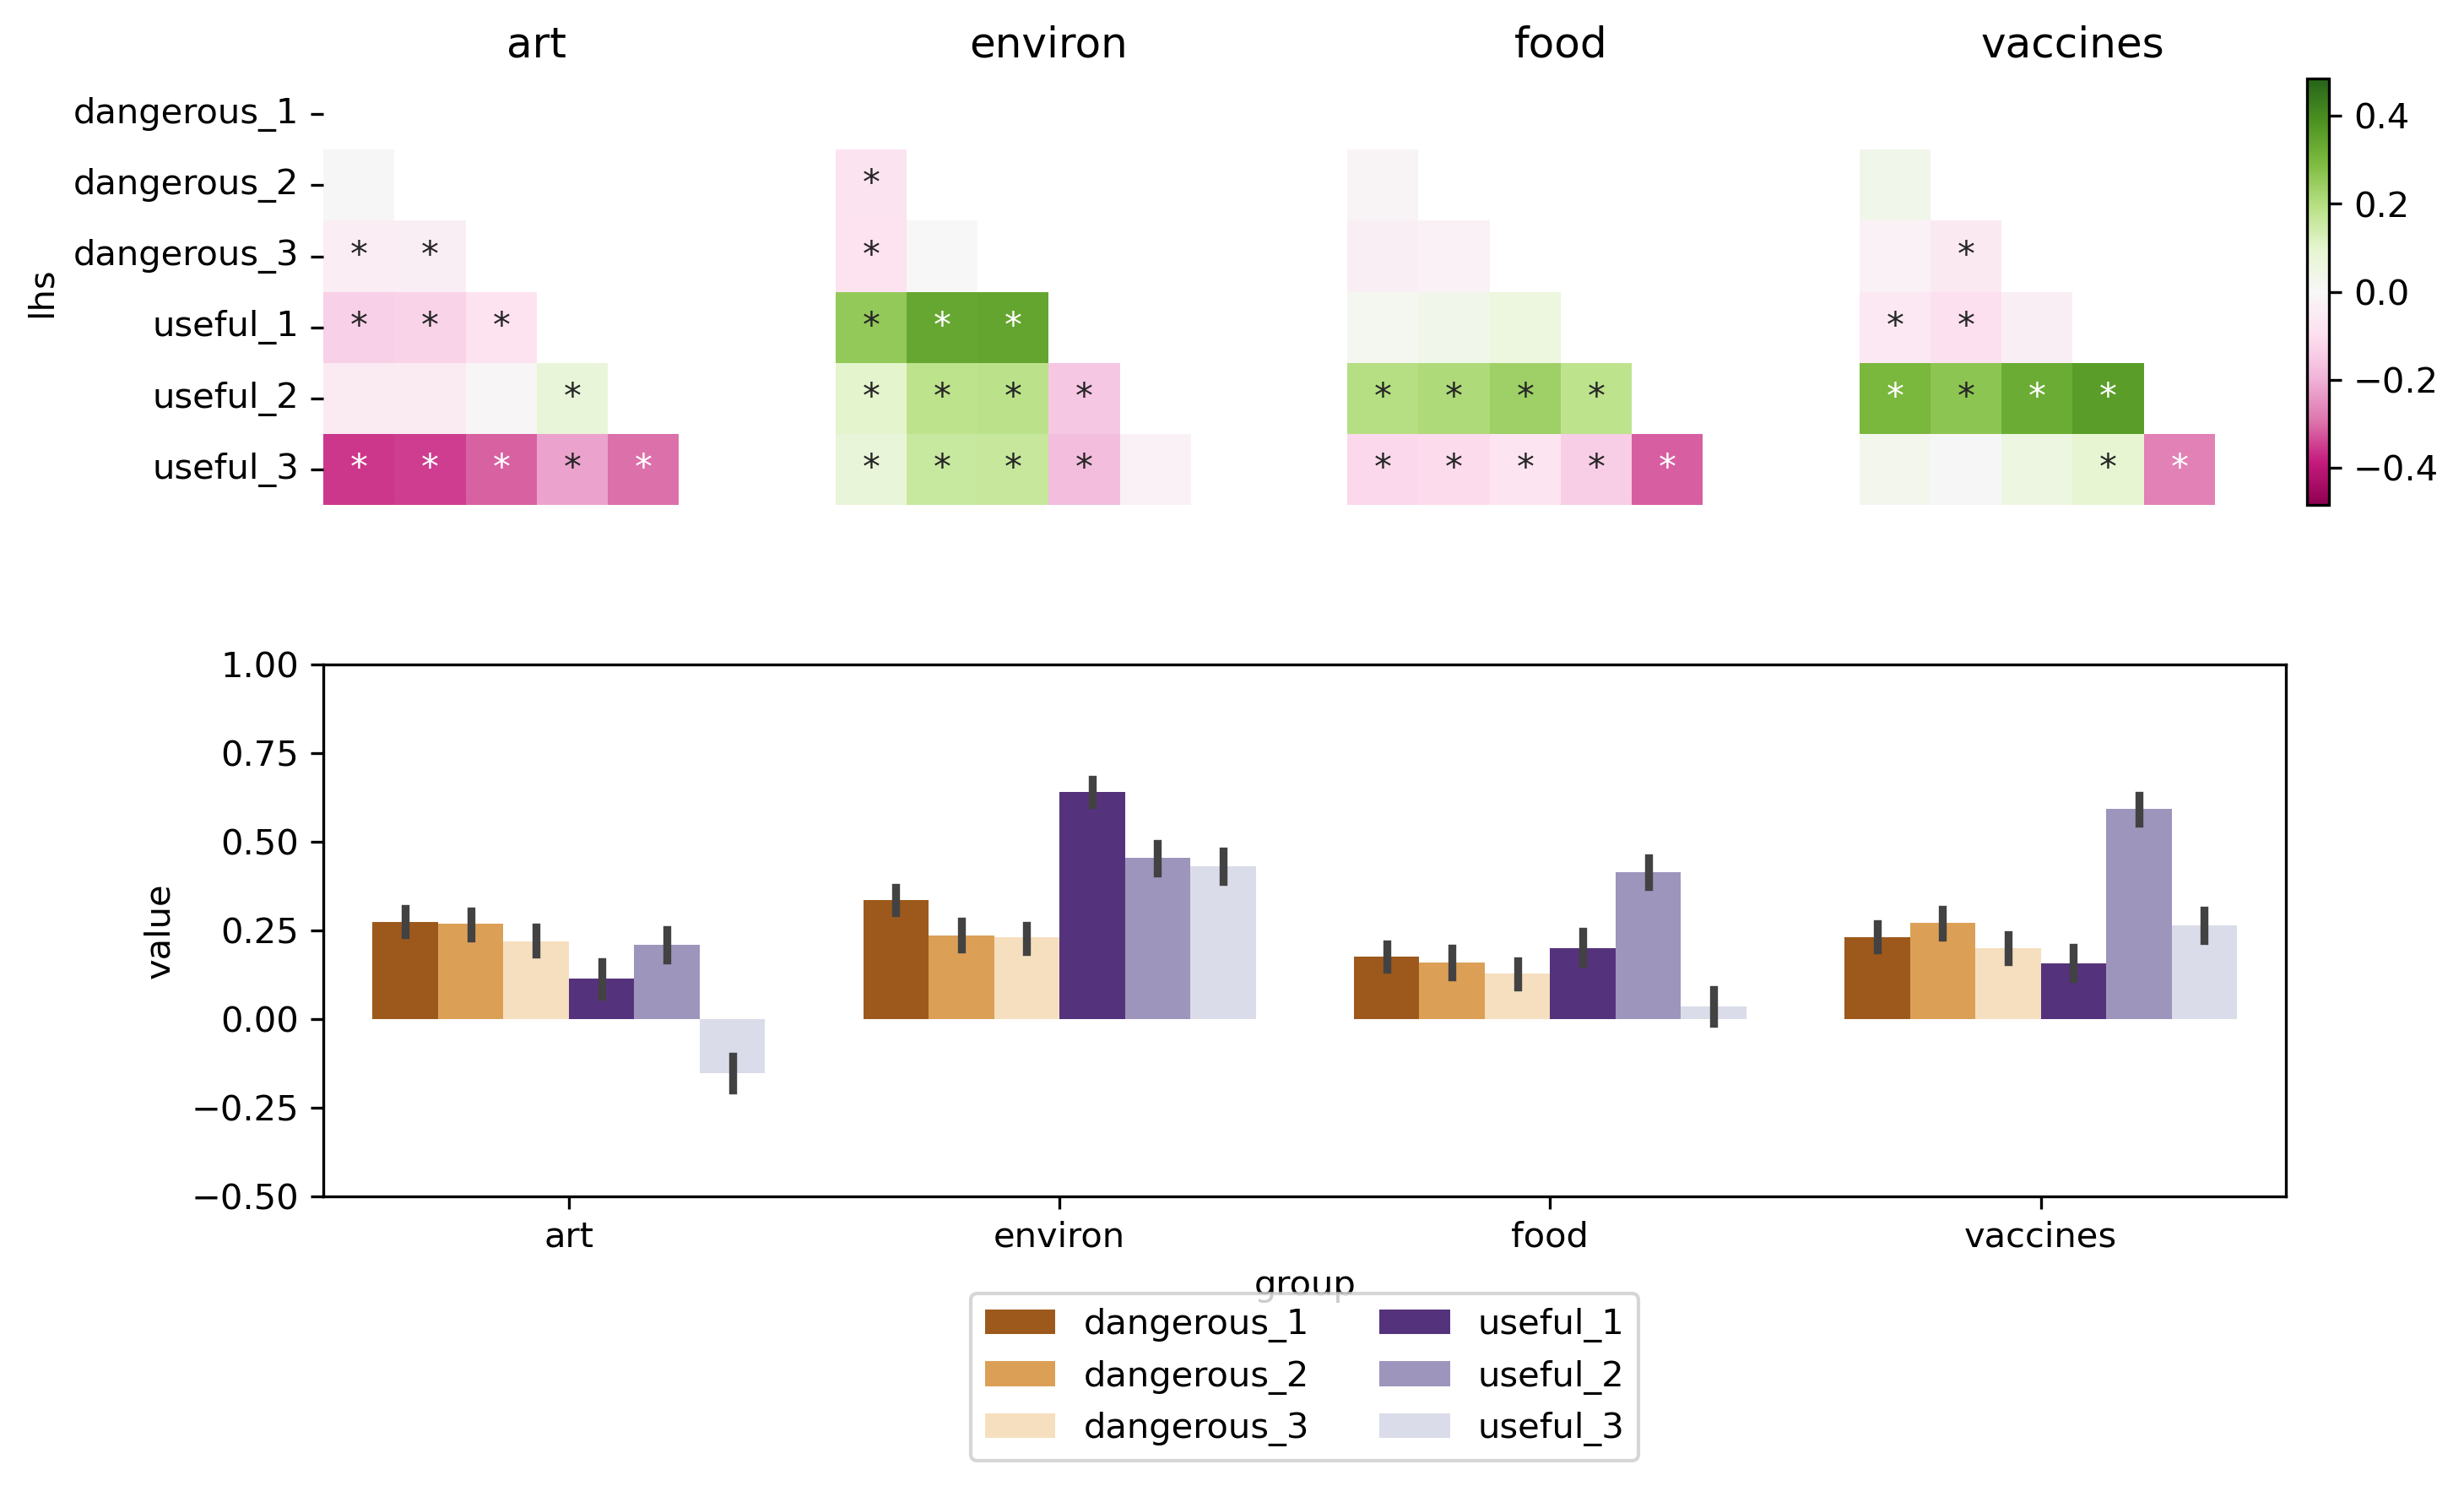

In [252]:
fig, axes = plt.subplot_mosaic("ABCD;EEEE", figsize=(10,6), dpi=300)
axes = list(axes.values())

corrs = {}

for i, g in enumerate(sorted(groups)):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    rprim.Estimate = -rprim.Estimate # OMG how did I miss this??
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = -1*r.pivot(index='lhs', columns='rhs', values='Estimate')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue').loc[table_e.index][table_e.index]
    table_e = table_e.rename(index={i: '_'.join(i.split('_')[1:]) for i in table_e.index})
    #upper_tri = 
    
    corrs[g] = table_e
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=min(res.Estimate), vmax=max(res.Estimate), center=0,  fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], res.Estimate, center=0, cmap="PiYG")

QC_melt = QC.reset_index().melt(value_vars=all_questions, id_vars=['prolific_pid'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[-1], palette=palette_questions)
axes[-1].set_ylim([-0.5, 1])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

fig.savefig('../results/question_effects.svg')
fig.savefig('../results/question_effects.png')

### Intergroup questions

/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/1899659794.py:20: FutureWarning: DataFrame.appl

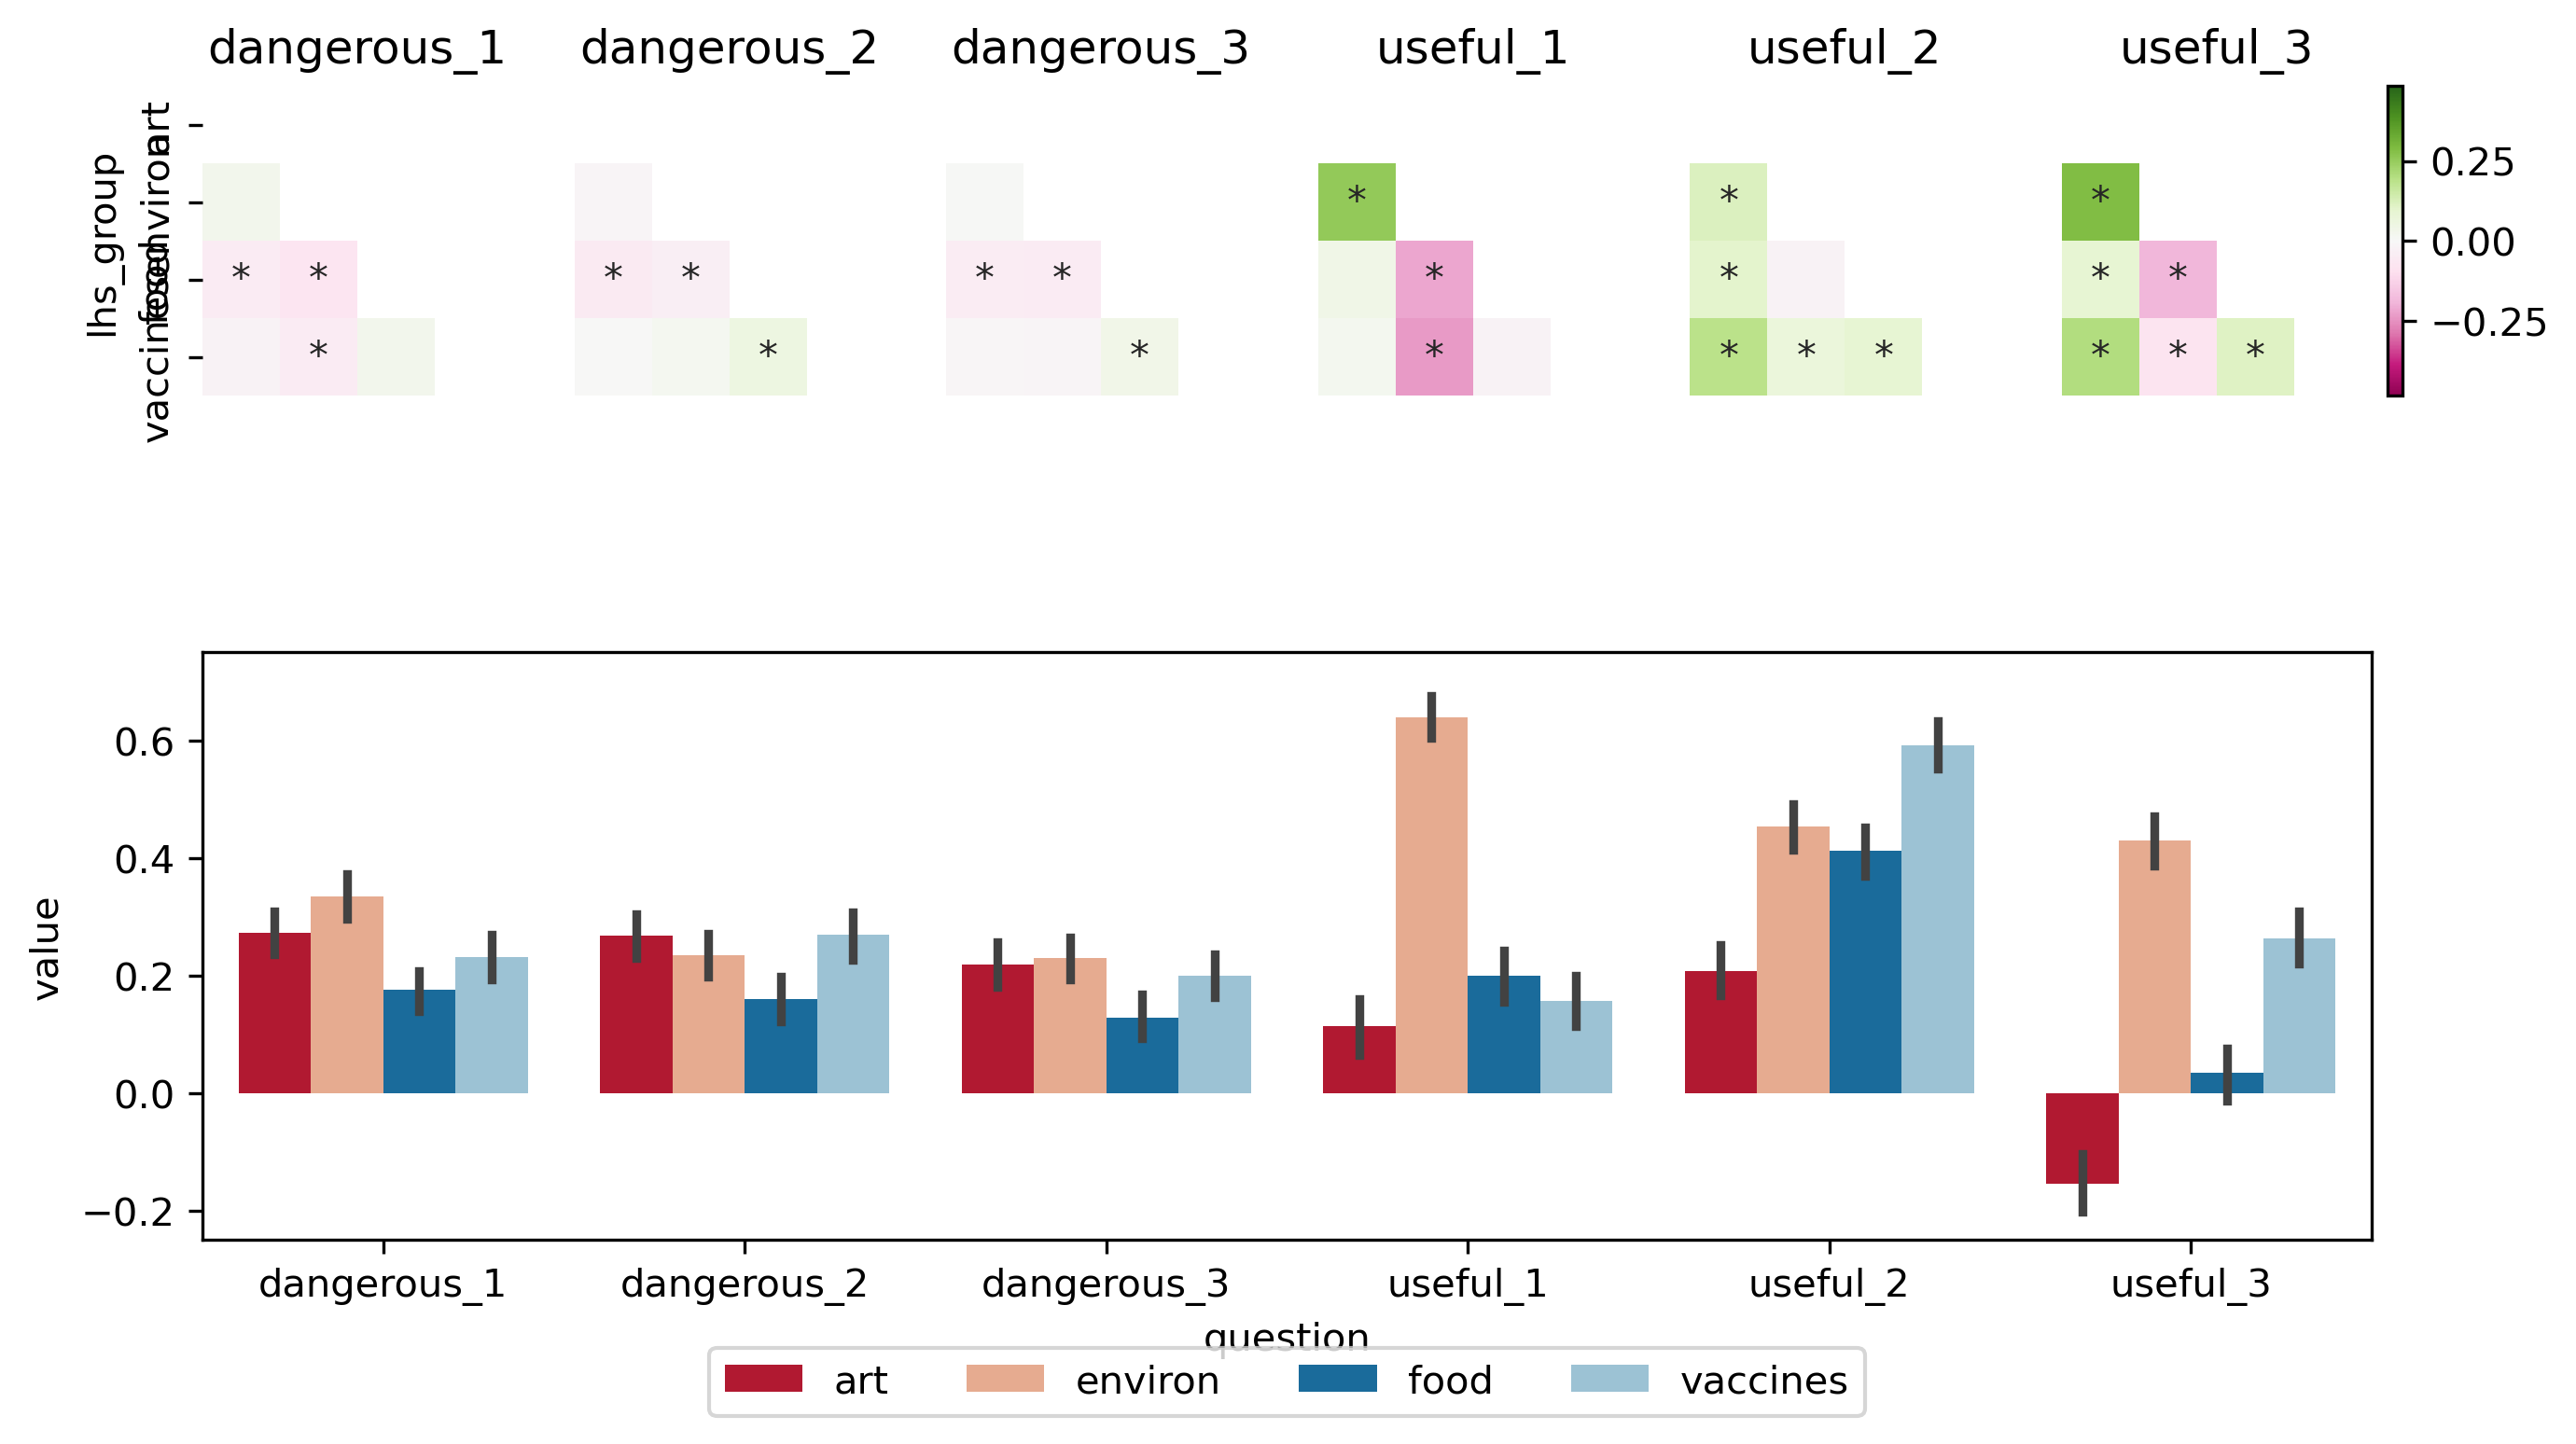

In [253]:
fig, axes = plt.subplot_mosaic("ABCDEF;GGGGGG", figsize=(10,6), dpi=300)
axes = list(axes.values())

#fig, axes = biu.utils.figure.subplots(figsize=(3*6,3), ncols=6, sharex=True, sharey=True)

for i, q in enumerate(sorted(group_questions)):
    r = res[(res.lhs_question == q) & (res.rhs_question == q)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    rprim.Estimate = -rprim.Estimate
    r = pd.concat([r, rprim]).drop_duplicates(['lhs','rhs'])
    
    table_e = -1*r.pivot(index='lhs_group', columns='rhs_group', values='Estimate')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs_group', columns='rhs_group', values='qvalue').loc[table_e.index][table_e.index]
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(q)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], res.Estimate, center=0, cmap="PiYG")

QC_melt = QC.reset_index(names='index').melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='question', y='value', hue='group', data=QC_melt, ax=axes[-1], palette=palette_groups)
axes[-1].set_ylim([-0.25, 0.75])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)


fig.savefig('../results/group_effects.svg')
fig.savefig('../results/group_effects.png')

### Plot individual correlations

In [138]:
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

import scipy as sp

def plot_participants(g1, q1, g2, q2):
    fig, axes = biu.utils.figure.subplots()

    d1 = '%s_%s' % (g1, q1)
    d2 = '%s_%s' % (g2, q2)

    sns.kdeplot(x=d1, y=d2, data=QC, fill=True, ax=axes[0])
    sns.regplot(x=d1, y=d2, data=QC, color=plt.get_cmap('tab10')(1), ax=axes[0])

    print(d1, d2)
    qrel = QC[[d1,d2]].dropna()
    print (sp.stats.ttest_rel(qrel[d1], qrel[d2]))

    axes[0].set_title('plot')
    #axes[0].set_xlabel("log2(Ion count)")
    #axes[0].set_ylabel("Frequency")
#edef

interact(lambda g1, q1, g2, q2: plot_participants(g1,q1,g2,q2),
        g1=sorted(set([ c.split('_')[0] for c in QC.columns if '_' in c ])),
        q1=sorted(set([ '_'.join(c.split('_')[1:]) for c in QC.columns  if '_' in c])),
        g2=sorted(set([ c.split('_')[0] for c in QC.columns if '_' in c ])),
        q2=sorted(set([ '_'.join(c.split('_')[1:]) for c in QC.columns if '_' in c])))

interactive(children=(Dropdown(description='g1', options=('art', 'environ', 'food', 'vaccines'), value='art'),…

<function __main__.<lambda>(g1, q1, g2, q2)>

In [139]:
d1 = 'art_dangerous_1'
d2 = 'art_useful_3'

qrel = QC[[d1,d2]].dropna()
print (sp.stats.ttest_rel(qrel[d1], qrel[d2]))

TtestResult(statistic=np.float64(14.840975979569675), pvalue=np.float64(2.1748263259647278e-41), df=np.int64(488))


# -
# -
# -


# Previous approaches - Show same results, but methodology is unnecessarily complex

# Perform partial correlation analyses


In [16]:
R = biu.R()

In [254]:
results = []
for (X, Y), Z in formulas.items():

    r = R("""
        f1 <- as.formula(paste0(c(X, paste0(Z, collapse=' + ')), collapse=' ~ '))
        m1 <- lm(f1, data)
        r1 <- m1$residuals
        
        f2 <- as.formula(paste0(c(Y, paste0(Z, collapse=' + ')), collapse=' ~ '))
        m2 <- lm(f2, data)
        r2 <- m2$residuals
        
        p <- cor.test(r1, r2, method=method)
        p.orig <- cor.test(data[,X], data[,Y], method=method)

        
        r <- c(p$estimate, p$p.value, length(r1), p.orig$estimate)

        r

    """, push=dict(X=X, Y=Y, Z=Z, data=QC[[X, Y] + Z].dropna(), method='spearman'))
    r = tuple([ X, Y, tuple(Z), X.split('_')[0], Y.split('_')[0], '_'.join(X.split('_')[1:]), '_'.join(Y.split('_')[1:])  ] + list(r))
    results.append(r)
#efor

results = pd.DataFrame(results, columns=['lhs', 'rhs', 'Z', 'lhs_group', 'rhs_group', 'lhs_question', 'rhs_question', 'p', 'pvalue', 'n', 'p_orig'])
results['qvalue'] = biu.stats.p_adjust(results['pvalue'])



R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In cor.test.default(r1, r2, method = method) :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: 2:   
R callback write-console: In cor.test.default(data[, X], data[, Y], method = method) :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In cor.test.default(r1, r2, method = method) :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: 2:   
R callback write-console: In cor.test.default(data[, X], data[, Y], method = method) :  
R callback write-console: 
   
R callback write-console:  Cannot c

Text(0, 0.5, 'Partial correlation (spearman)')

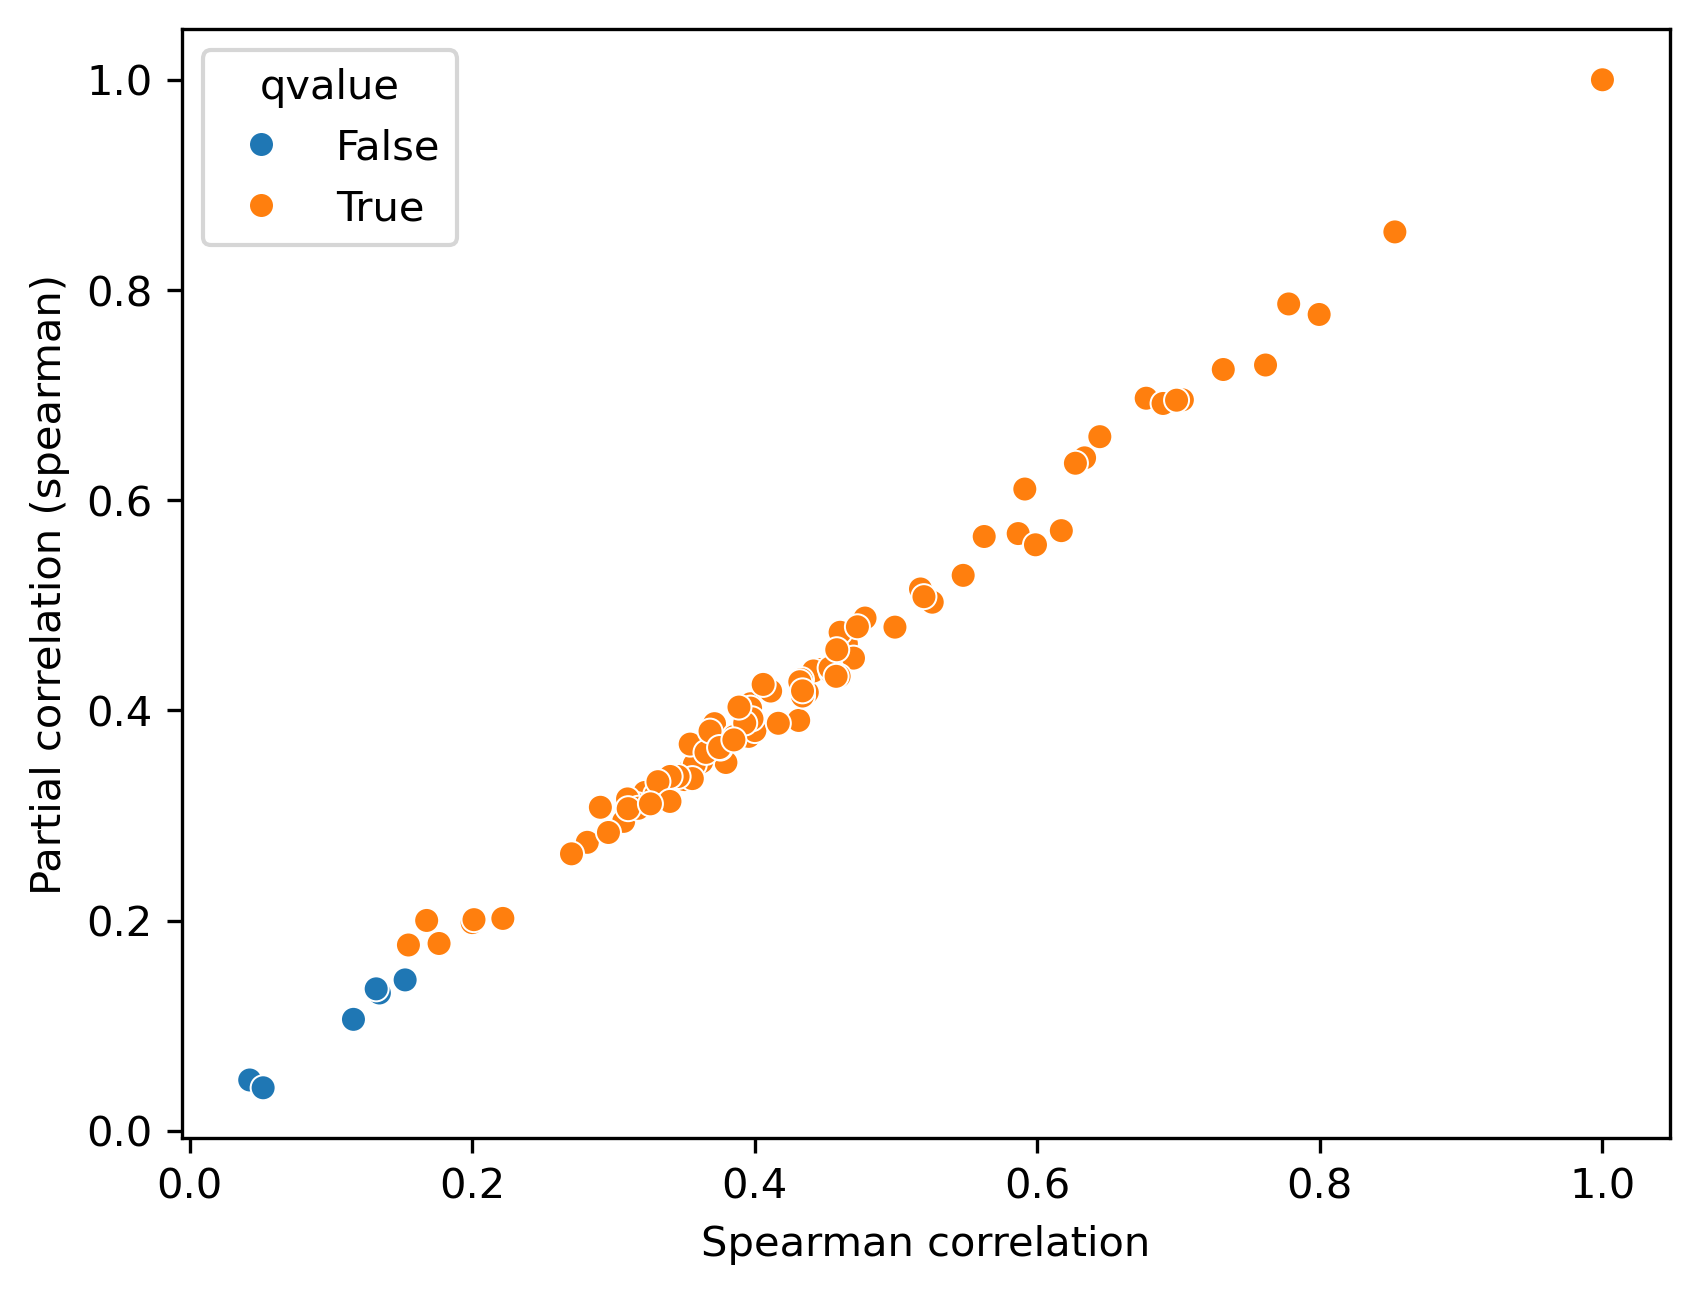

In [198]:
fig, axes = biu.utils.figure.subplots()
sns.scatterplot(x=results.p_orig, y=results.p, hue=results.qvalue < 0.05, ax=axes[0])
axes[0].set_xlabel('Spearman correlation')
axes[0].set_ylabel('Partial correlation (spearman)')

## Visualise

### Intragroup questions

/tmp/ipykernel_3628891/3739297758.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3739297758.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3739297758.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3739297758.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


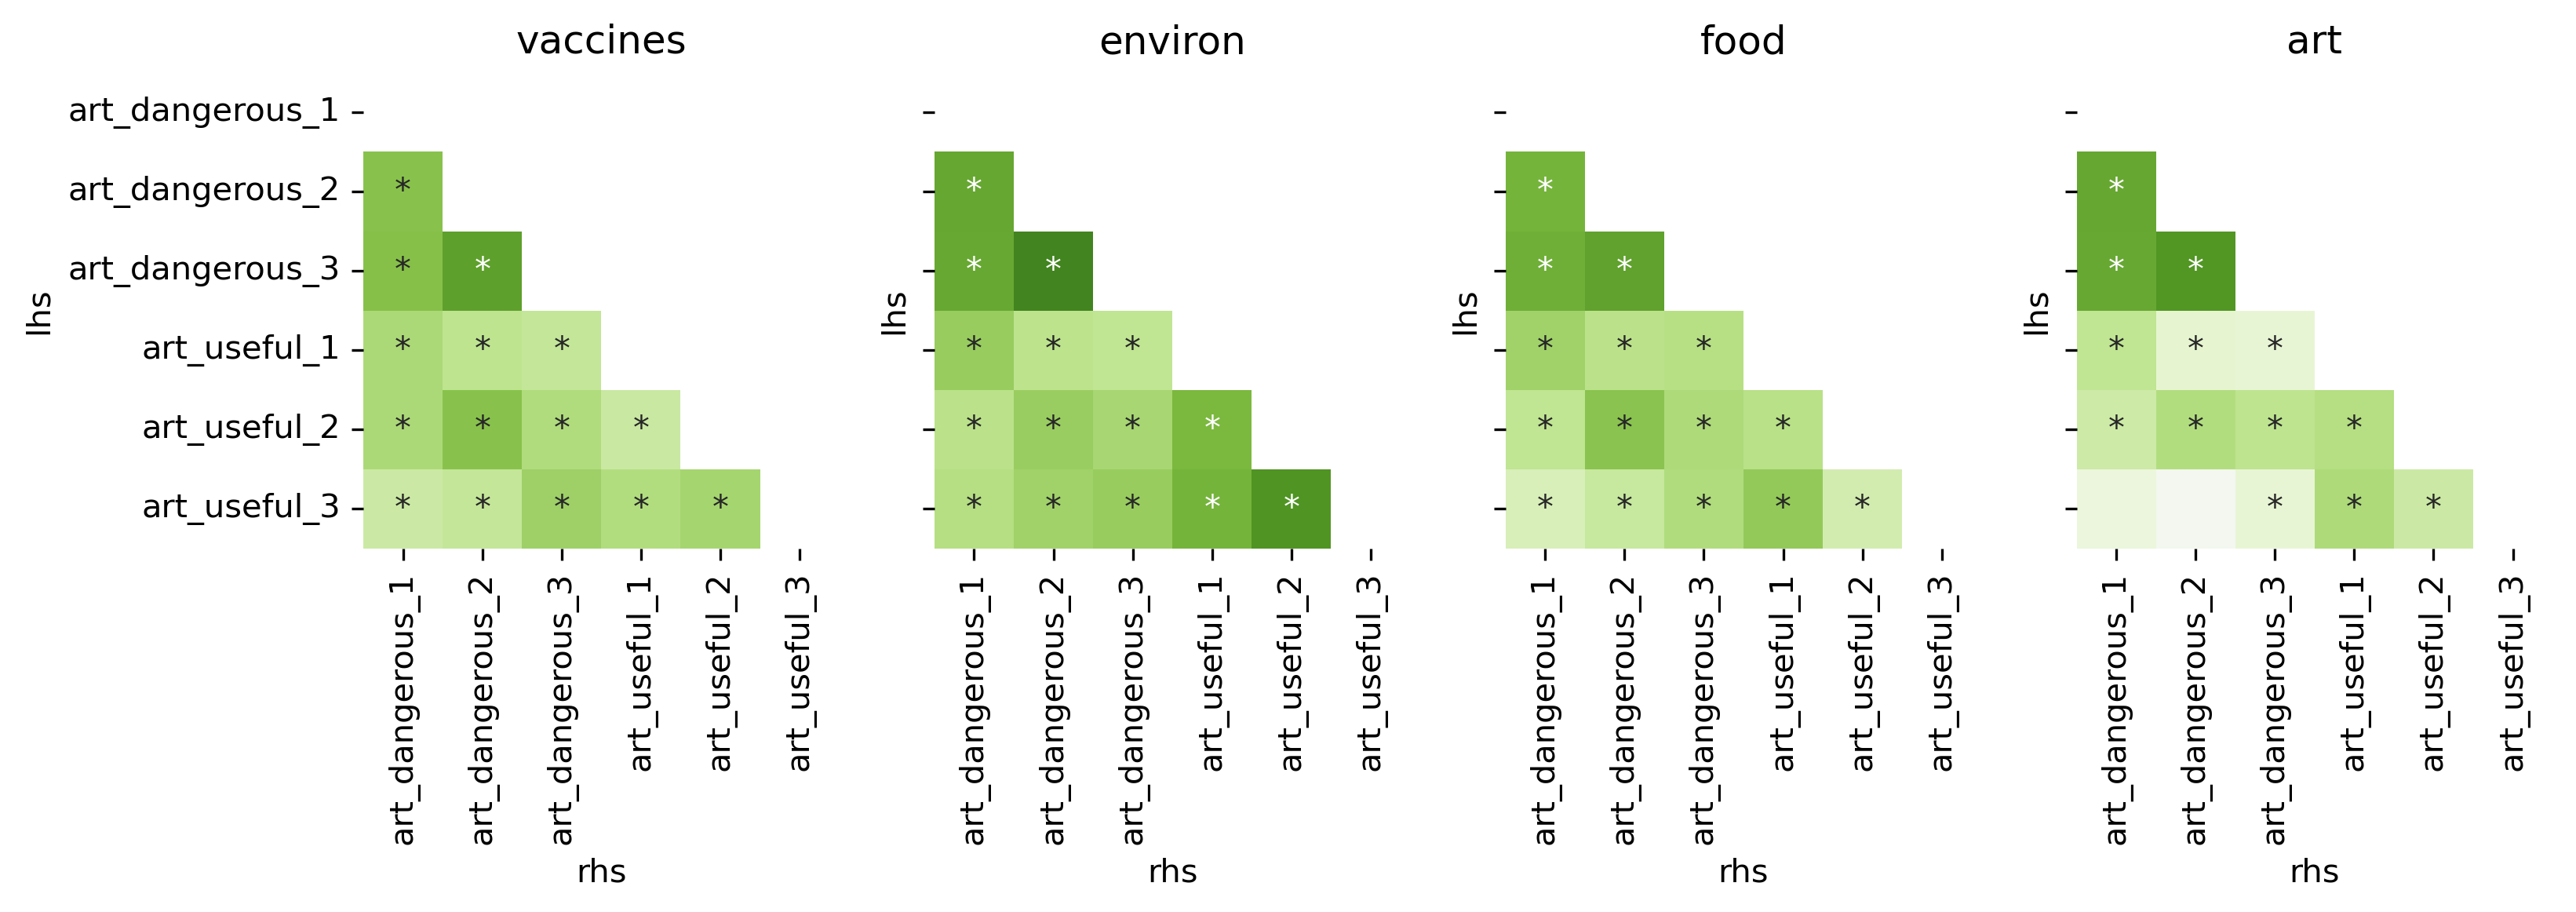

In [203]:
fig, axes = biu.utils.figure.subplots(figsize=(12,3), ncols=4, sharex=True, sharey=True)

for i, g in enumerate(groups):
    r = results[(results.lhs_group == g) & (results.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='p')
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue')
    #upper_tri = 
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, center=0, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),0) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
#efor

/tmp/ipykernel_3628891/3784497722.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3784497722.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3784497722.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3784497722.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


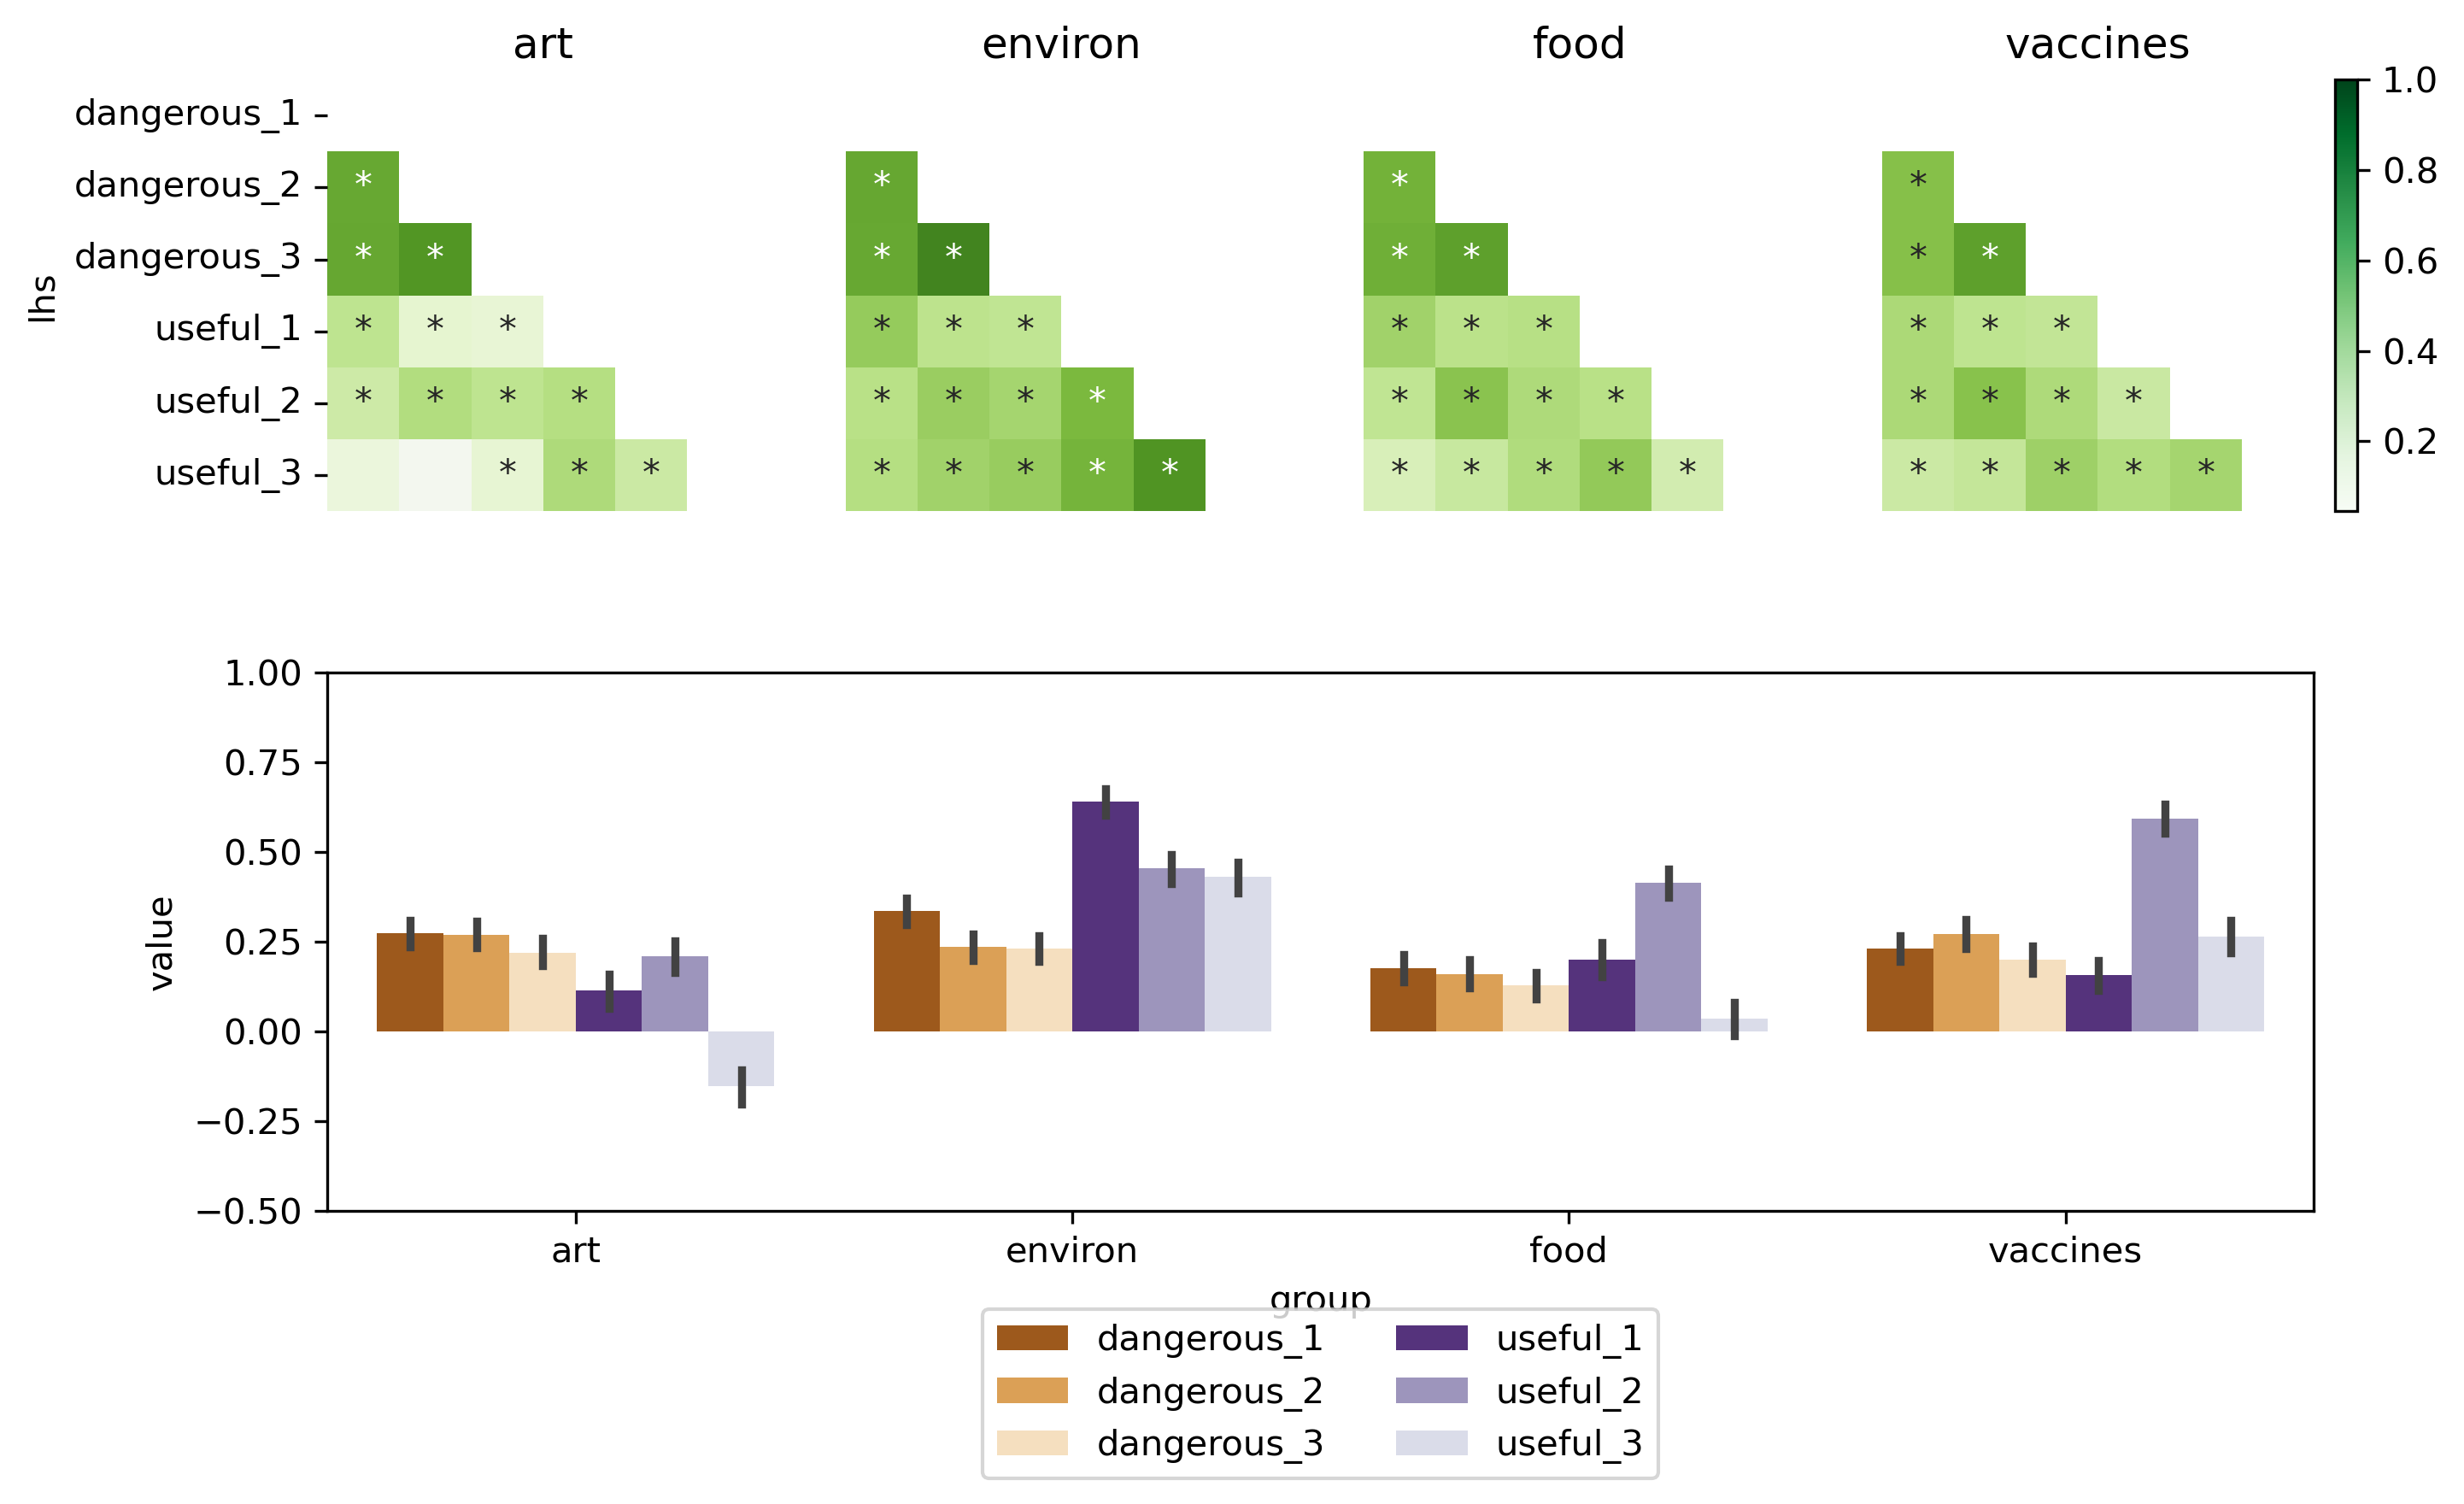

In [258]:
fig, axes = plt.subplot_mosaic("ABCD;EEEE", figsize=(10,6), dpi=300)
axes = list(axes.values())

corrs = {}

for i, g in enumerate(sorted(groups)):
    r = results[(results.lhs_group == g) & (results.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='p')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue').loc[table_e.index][table_e.index]
    table_e = table_e.rename(index={i: '_'.join(i.split('_')[1:]) for i in table_e.index})
    #upper_tri = 
    
    corrs[g] = table_e
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),0) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], results.p, cmap="Greens")

QC_melt = QC.reset_index(names='index').melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[-1], palette=palette_questions)
axes[-1].set_ylim([-0.5, 1])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

fig.savefig('../results/question_corr.svg')
fig.savefig('../results/question_corr.png')

### Additional analysis

##### for g in corrs:
    x = corrs[g].rename(columns={c : '_'.join(c.split('_')[1:]) for c in corrs[g].columns})
    y = x.values[np.tril_indices_from(x, -1)]
    
    print("%s, q-value=%f" % (g, scipy.stats.ranksums(y[:3], y[3:]).pvalue*4))
#efor

In [537]:
x

rhs,dangerous_1,dangerous_2,dangerous_3,useful_1,useful_2,useful_3
lhs,,,,,,
dangerous_1,1.000000,0.569568,0.571678,0.436776,0.435518,0.315968
dangerous_2,0.569568,1.000000,0.730150,0.367540,0.562272,0.340910
dangerous_3,0.571678,0.730150,1.000000,0.348904,0.424672,0.482964
useful_1,0.436776,0.367540,0.348904,1.000000,0.323063,0.419729
useful_2,0.435518,0.562272,0.424672,0.323063,1.000000,0.466247
useful_3,0.315968,0.340910,0.482964,0.419729,0.466247,1.000000


In [538]:
y

array([0.56956753, 0.57167756, 0.73014951, 0.43677613, 0.36753963,
       0.34890415, 0.43551808, 0.56227159, 0.42467202, 0.32306317,
       0.31596752, 0.34091032, 0.48296352, 0.41972867, 0.4662472 ])

### Intergroup questions

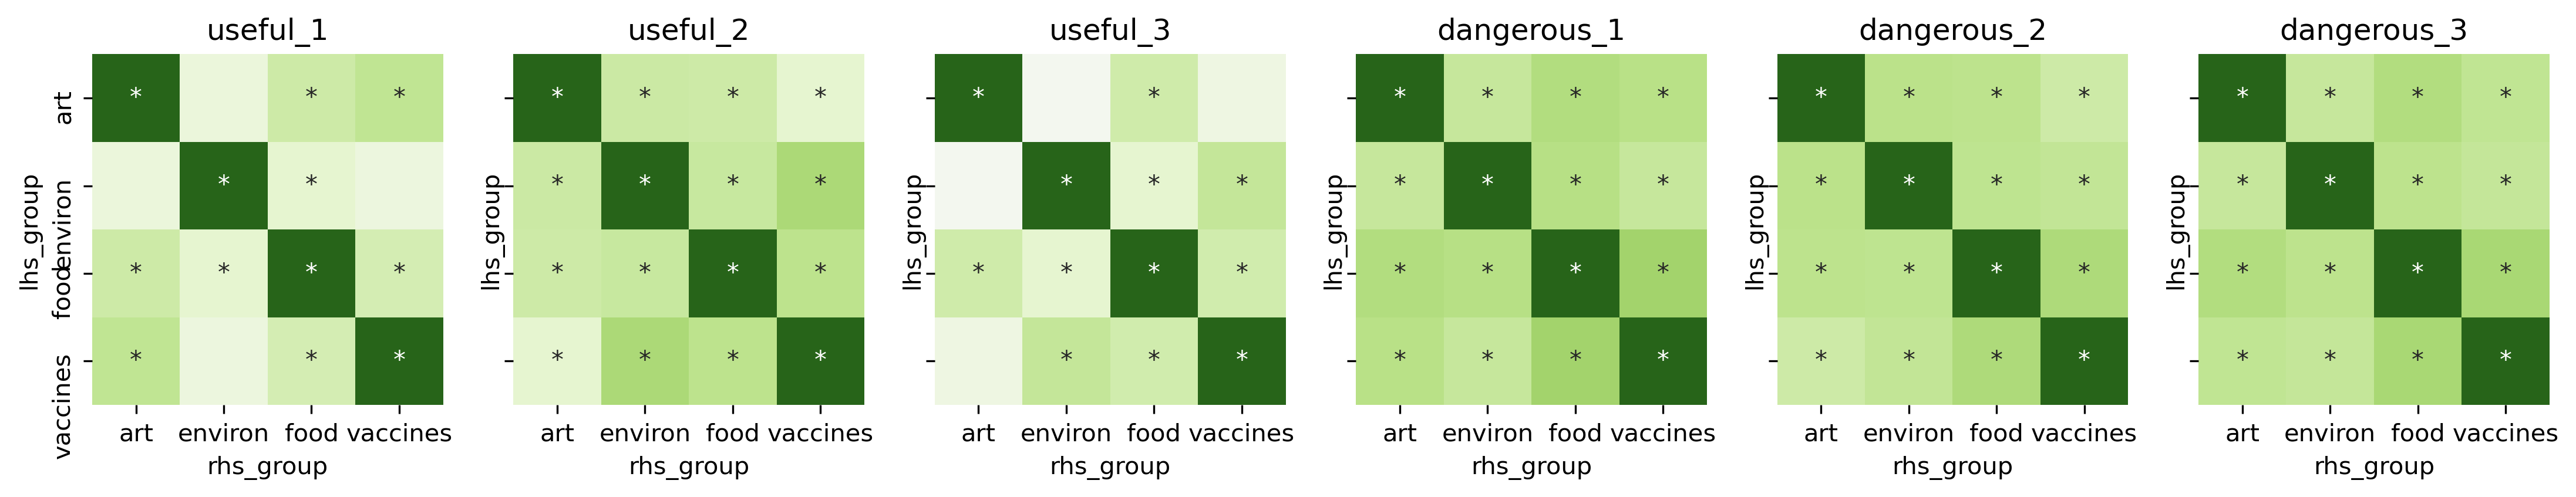

In [407]:
fig, axes = biu.utils.figure.subplots(figsize=(3*6,3), ncols=6, sharex=True, sharey=True)

for i, q in enumerate(sorted(group_questions)):
    r = results[(results.lhs_question == q) & (results.rhs_question == q)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates(['lhs','rhs'])
    
    table_e = r.pivot(index='lhs_group', columns='rhs_group', values='p')
    table_p = r.pivot(index='lhs_group', columns='rhs_group', values='qvalue')
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(q)
#efor

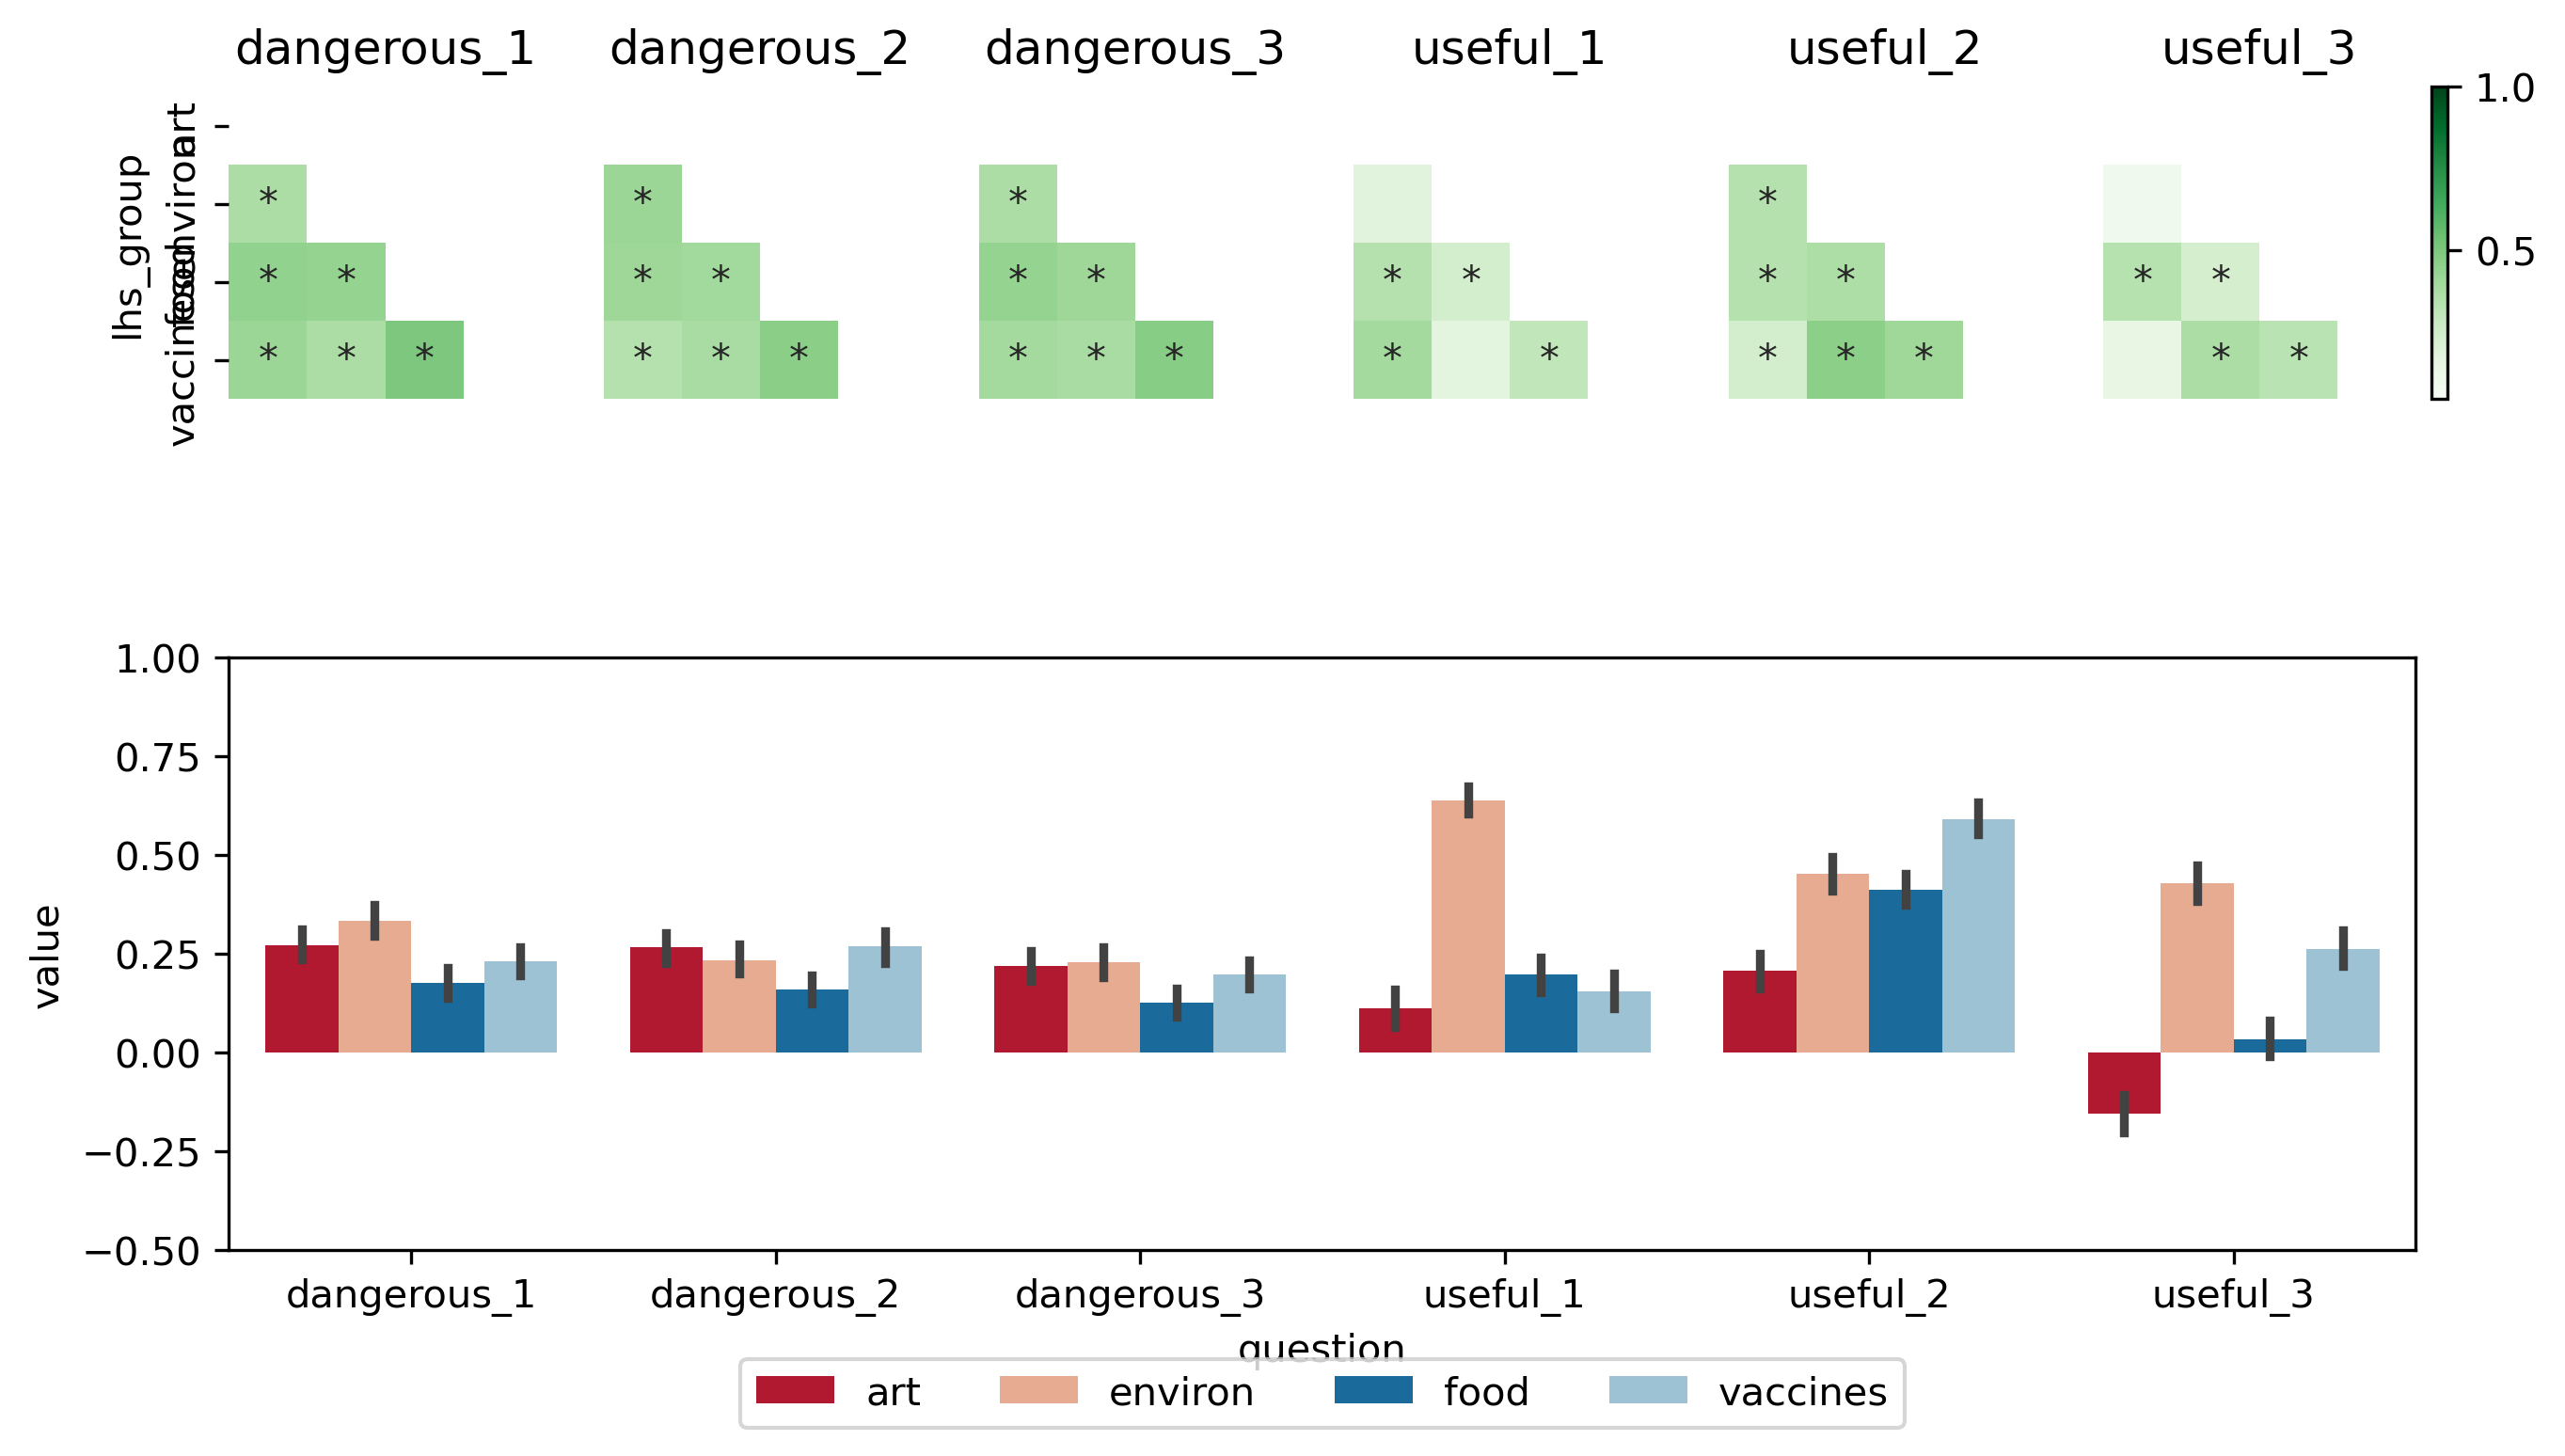

In [259]:
fig, axes = plt.subplot_mosaic("ABCDEF;GGGGGG", figsize=(10,6), dpi=300)
axes = list(axes.values())

#fig, axes = biu.utils.figure.subplots(figsize=(3*6,3), ncols=6, sharex=True, sharey=True)

for i, q in enumerate(sorted(group_questions)):
    r = results[(results.lhs_question == q) & (results.rhs_question == q)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates(['lhs','rhs'])
    
    table_e = r.pivot(index='lhs_group', columns='rhs_group', values='p')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs_group', columns='rhs_group', values='qvalue').loc[table_e.index][table_e.index]
    
    sns.heatmap(table_e, ax=axes[i], cmap='Greens', vmin=0, vmax=1, fmt='s',
                annot=(table_p < 0.05).map(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),0) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(q)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], results.p, cmap="Greens")

QC_melt = QC.reset_index(names='index').melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='question', y='value', hue='group', data=QC_melt, ax=axes[-1], palette=palette_groups)
axes[-1].set_ylim([-0.5, 1])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)

fig.savefig('../results/group_corr.svg')
fig.savefig('../results/group_corr.png')

In [504]:
QC

,vaccines_useful_1,vaccines_useful_2,vaccines_useful_3,vaccines_dangerous_1,vaccines_dangerous_2,vaccines_dangerous_3,environ_useful_1,environ_useful_2,environ_useful_3,environ_dangerous_1,...,vaccines_knowledge,environ_knowledge,food_knowledge,art_knowledge,age,sex,ethnicity,birthcountry,residence,nationality
54ccac0dfdf99b3a7712573d,0.0,0.5,0.5,0.0,-0.5,-0.5,0.5,0.5,0.0,0.5,...,True,True,True,False,49,Male,White,United Kingdom,United Kingdom,United Kingdom
55898d0ffdf99b7ae47f5d45,-1.0,0.5,0.0,0.5,0.0,0.0,0.5,0.5,0.5,0.5,...,False,False,False,False,32,Male,White,United States,United States,United States
558996f2fdf99b7ae47f5ed2,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,False,True,True,False,38,Male,White,United Kingdom,United Kingdom,United Kingdom
55cdc77f34e90600128d237f,0.5,0.5,-1.0,0.5,0.5,0.5,-0.5,-0.5,-0.5,-0.5,...,True,False,True,False,38,Female,White,United Kingdom,United Kingdom,United Kingdom
561d26063d7fe800110f5ac0,0.5,1.0,0.0,0.5,0.5,0.0,1.0,0.0,0.5,0.5,...,False,True,False,True,58,Female,White,United Kingdom,United Kingdom,United Kingdom
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67221888aa00b953800ae6d1,0.5,0.5,0.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,True,True,True,False,26,Female,Black,Nigeria,United Kingdom,Nigeria
67223c6474a28cae8a6248b7,0.5,1.0,0.0,0.5,0.5,0.0,0.5,0.5,-0.5,0.5,...,True,False,True,False,40,Female,Asian,India,United Kingdom,United Kingdom
672240fa735fc09f3c8d4581,0.5,1.0,0.5,0.5,0.5,0.5,0.0,0.5,0.5,0.5,...,False,True,True,True,44,Female,Black,United Kingdom,South Africa,South Africa
67224e48f4f4f3fff687820f,-1.0,0.5,0.5,0.0,0.0,0.0,1.0,0.5,-0.5,0.5,...,True,True,True,False,26,Female,White,United States,United States,United States


# Perform partial differential analyses


In [16]:
R = biu.R()

In [140]:
res_pds = []
for (X, Y), Z in formulas.items():

    if X == Y:
        continue
    #fi

    r = R("""
        f1 <- as.formula(paste0(c(X, paste0(Z, collapse=' + ')), collapse=' ~ '))
        m1 <- lm(f1, data)
        r1 <- m1$residuals
        
        f2 <- as.formula(paste0(c(Y, paste0(Z, collapse=' + ')), collapse=' ~ '))
        m2 <- lm(f2, data)
        r2 <- m2$residuals
        
        t <- t.test(r1, r2, paired=TRUE)
        t.orig <- t.test(data[,X], data[,Y], paired=TRUE)
        
        r <- c(t$statistic, t$p.value, length(r1), t.orig$statistic, t.orig$p.value)

        r

    """, push=dict(X=X, Y=Y, Z=Z, data=QC[[X, Y] + Z].dropna()))
    r = tuple([ X, Y, tuple(Z), X.split('_')[0], Y.split('_')[0], '_'.join(X.split('_')[1:]), '_'.join(Y.split('_')[1:])  ] + list(r))
    res_pds.append(r)
#efor

res_pds = pd.DataFrame(res_pds, columns=['lhs', 'rhs', 'Z', 'lhs_group', 'rhs_group', 'lhs_question', 'rhs_question', 'Estimate', 'pvalue', 'n', 'e_orig', 'p_orig'])
res_pds['qvalue'] = biu.stats.p_adjust(res_pds['pvalue'])



Text(0, 0.5, 'Partial correlation (spearman)')

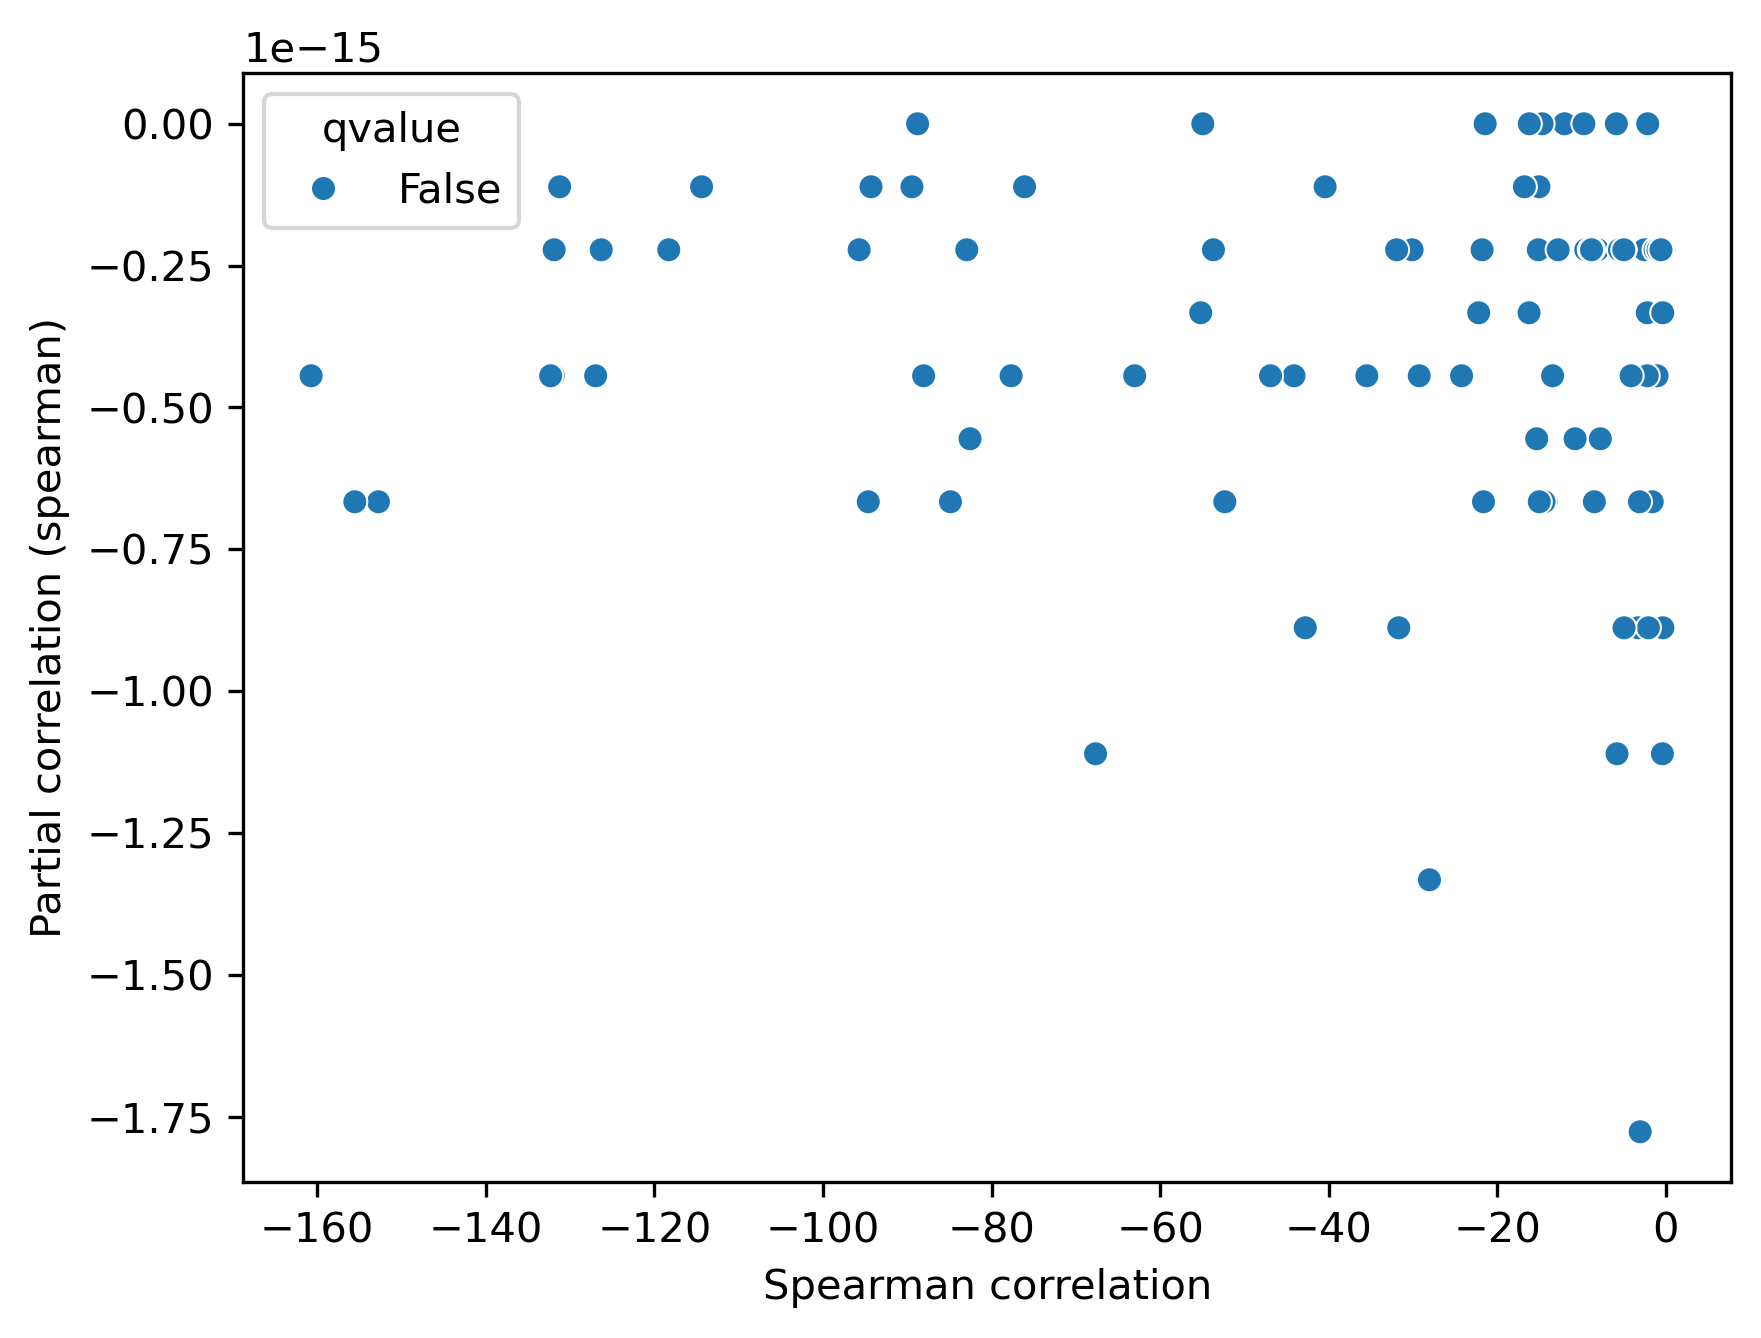

In [141]:
fig, axes = biu.utils.figure.subplots()
sns.scatterplot(x=np.log(res_pds.p_orig), y=np.log(res_pds.pvalue), hue=res_pds.qvalue < 0.05, ax=axes[0])
axes[0].set_xlabel('Spearman correlation')
axes[0].set_ylabel('Partial correlation (spearman)')

In [149]:
R("""
names(t)
""")

array(['statistic', 'parameter', 'p.value', 'conf.int', 'estimate',
       'null.value', 'stderr', 'alternative', 'method', 'data.name'],
      dtype='<U11')

## Visualise

In [147]:
res = res_pds

res_pds[res_pds.pvalue < 0.05]

,lhs,rhs,Z,lhs_group,rhs_group,lhs_question,rhs_question,Estimate,pvalue,n,e_orig,p_orig,qvalue


### Intragroup questions

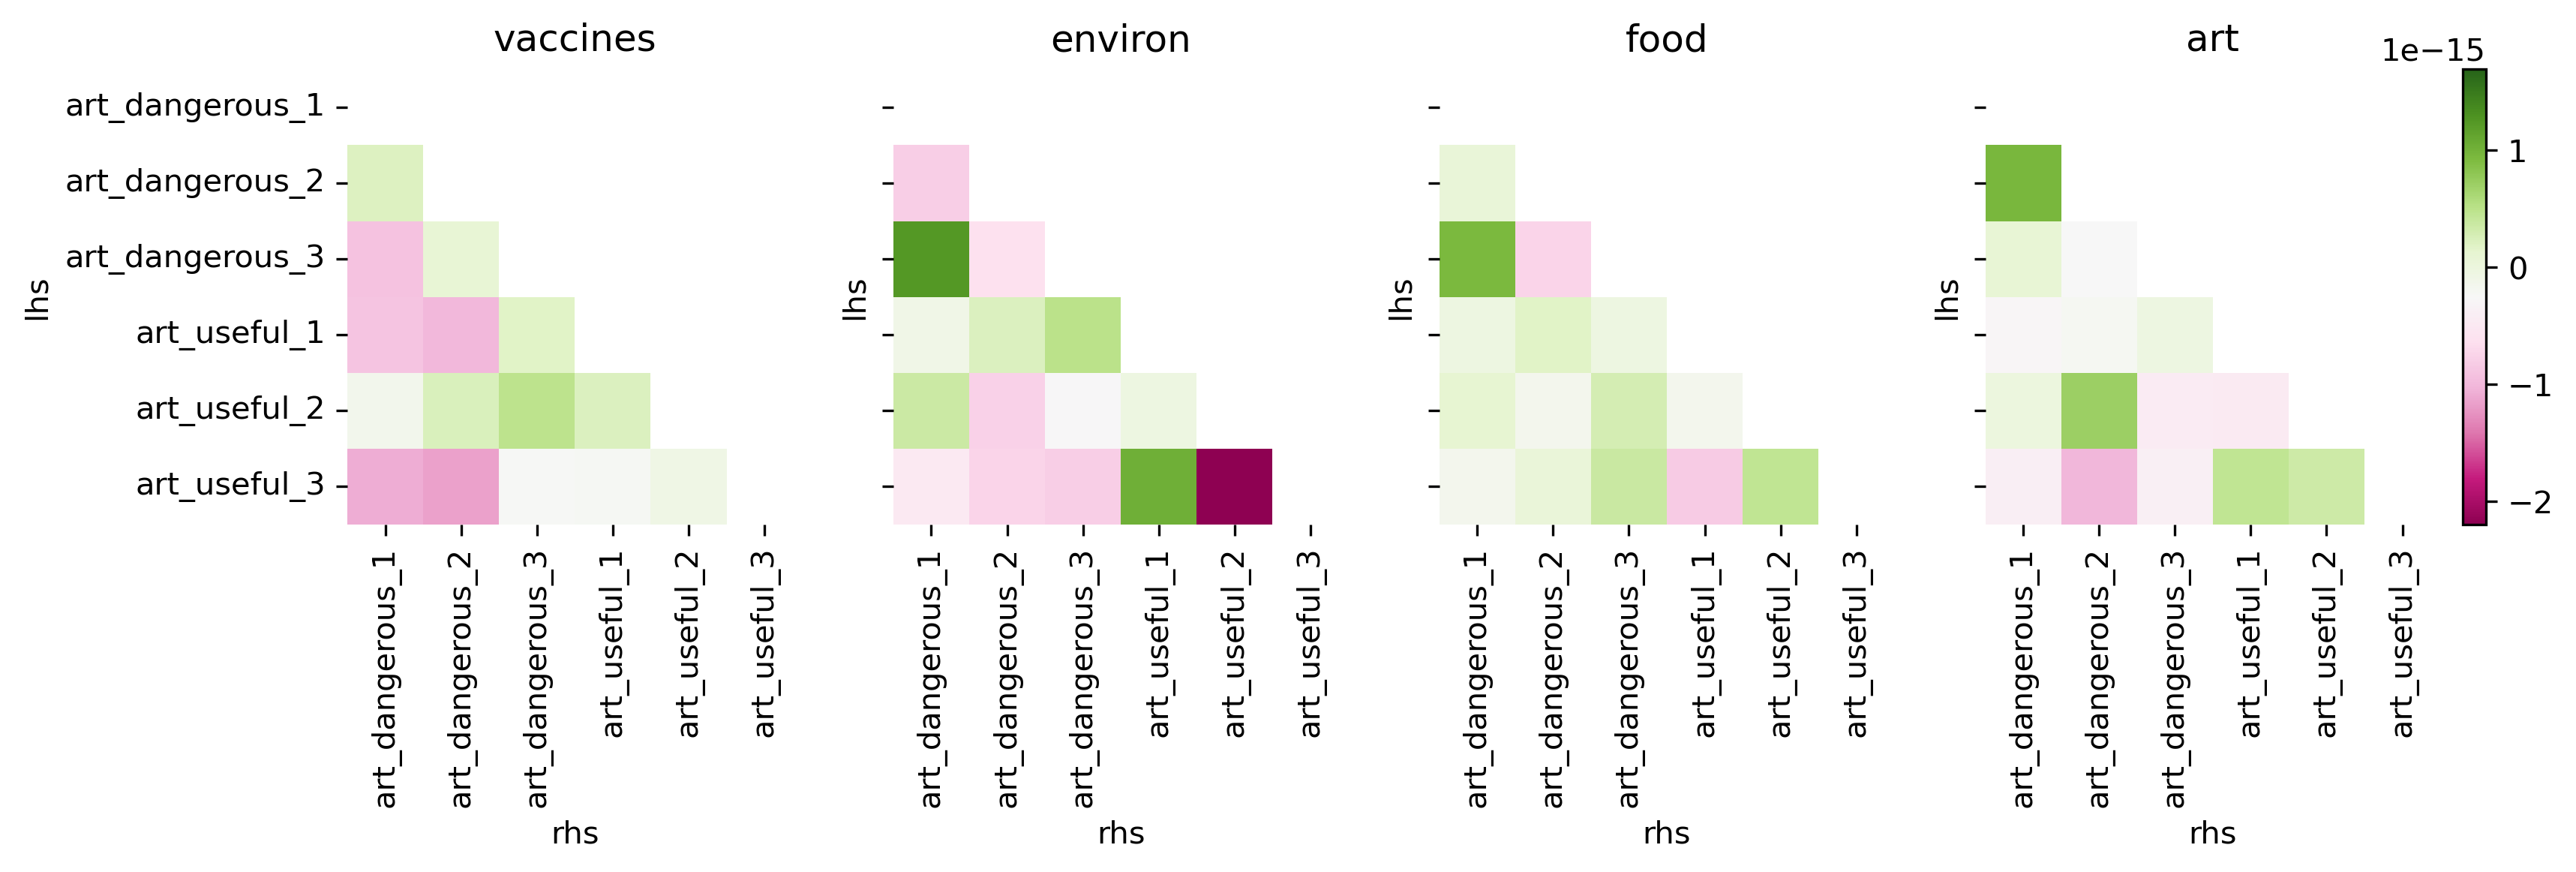

In [144]:
fig, axes = biu.utils.figure.subplots(figsize=(12,3), ncols=4, sharex=True, sharey=True)

for i, g in enumerate(groups):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='Estimate')
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue')
    #upper_tri = 
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=min(res.Estimate), vmax=max(res.Estimate), center=0, fmt='s',
                annot=(table_p < 0.05).map(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
#efor

move_colorbar(axes[-1], res.Estimate, cmap="PiYG")

/tmp/ipykernel_3628891/3753545051.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3753545051.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3753545051.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/3753545051.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


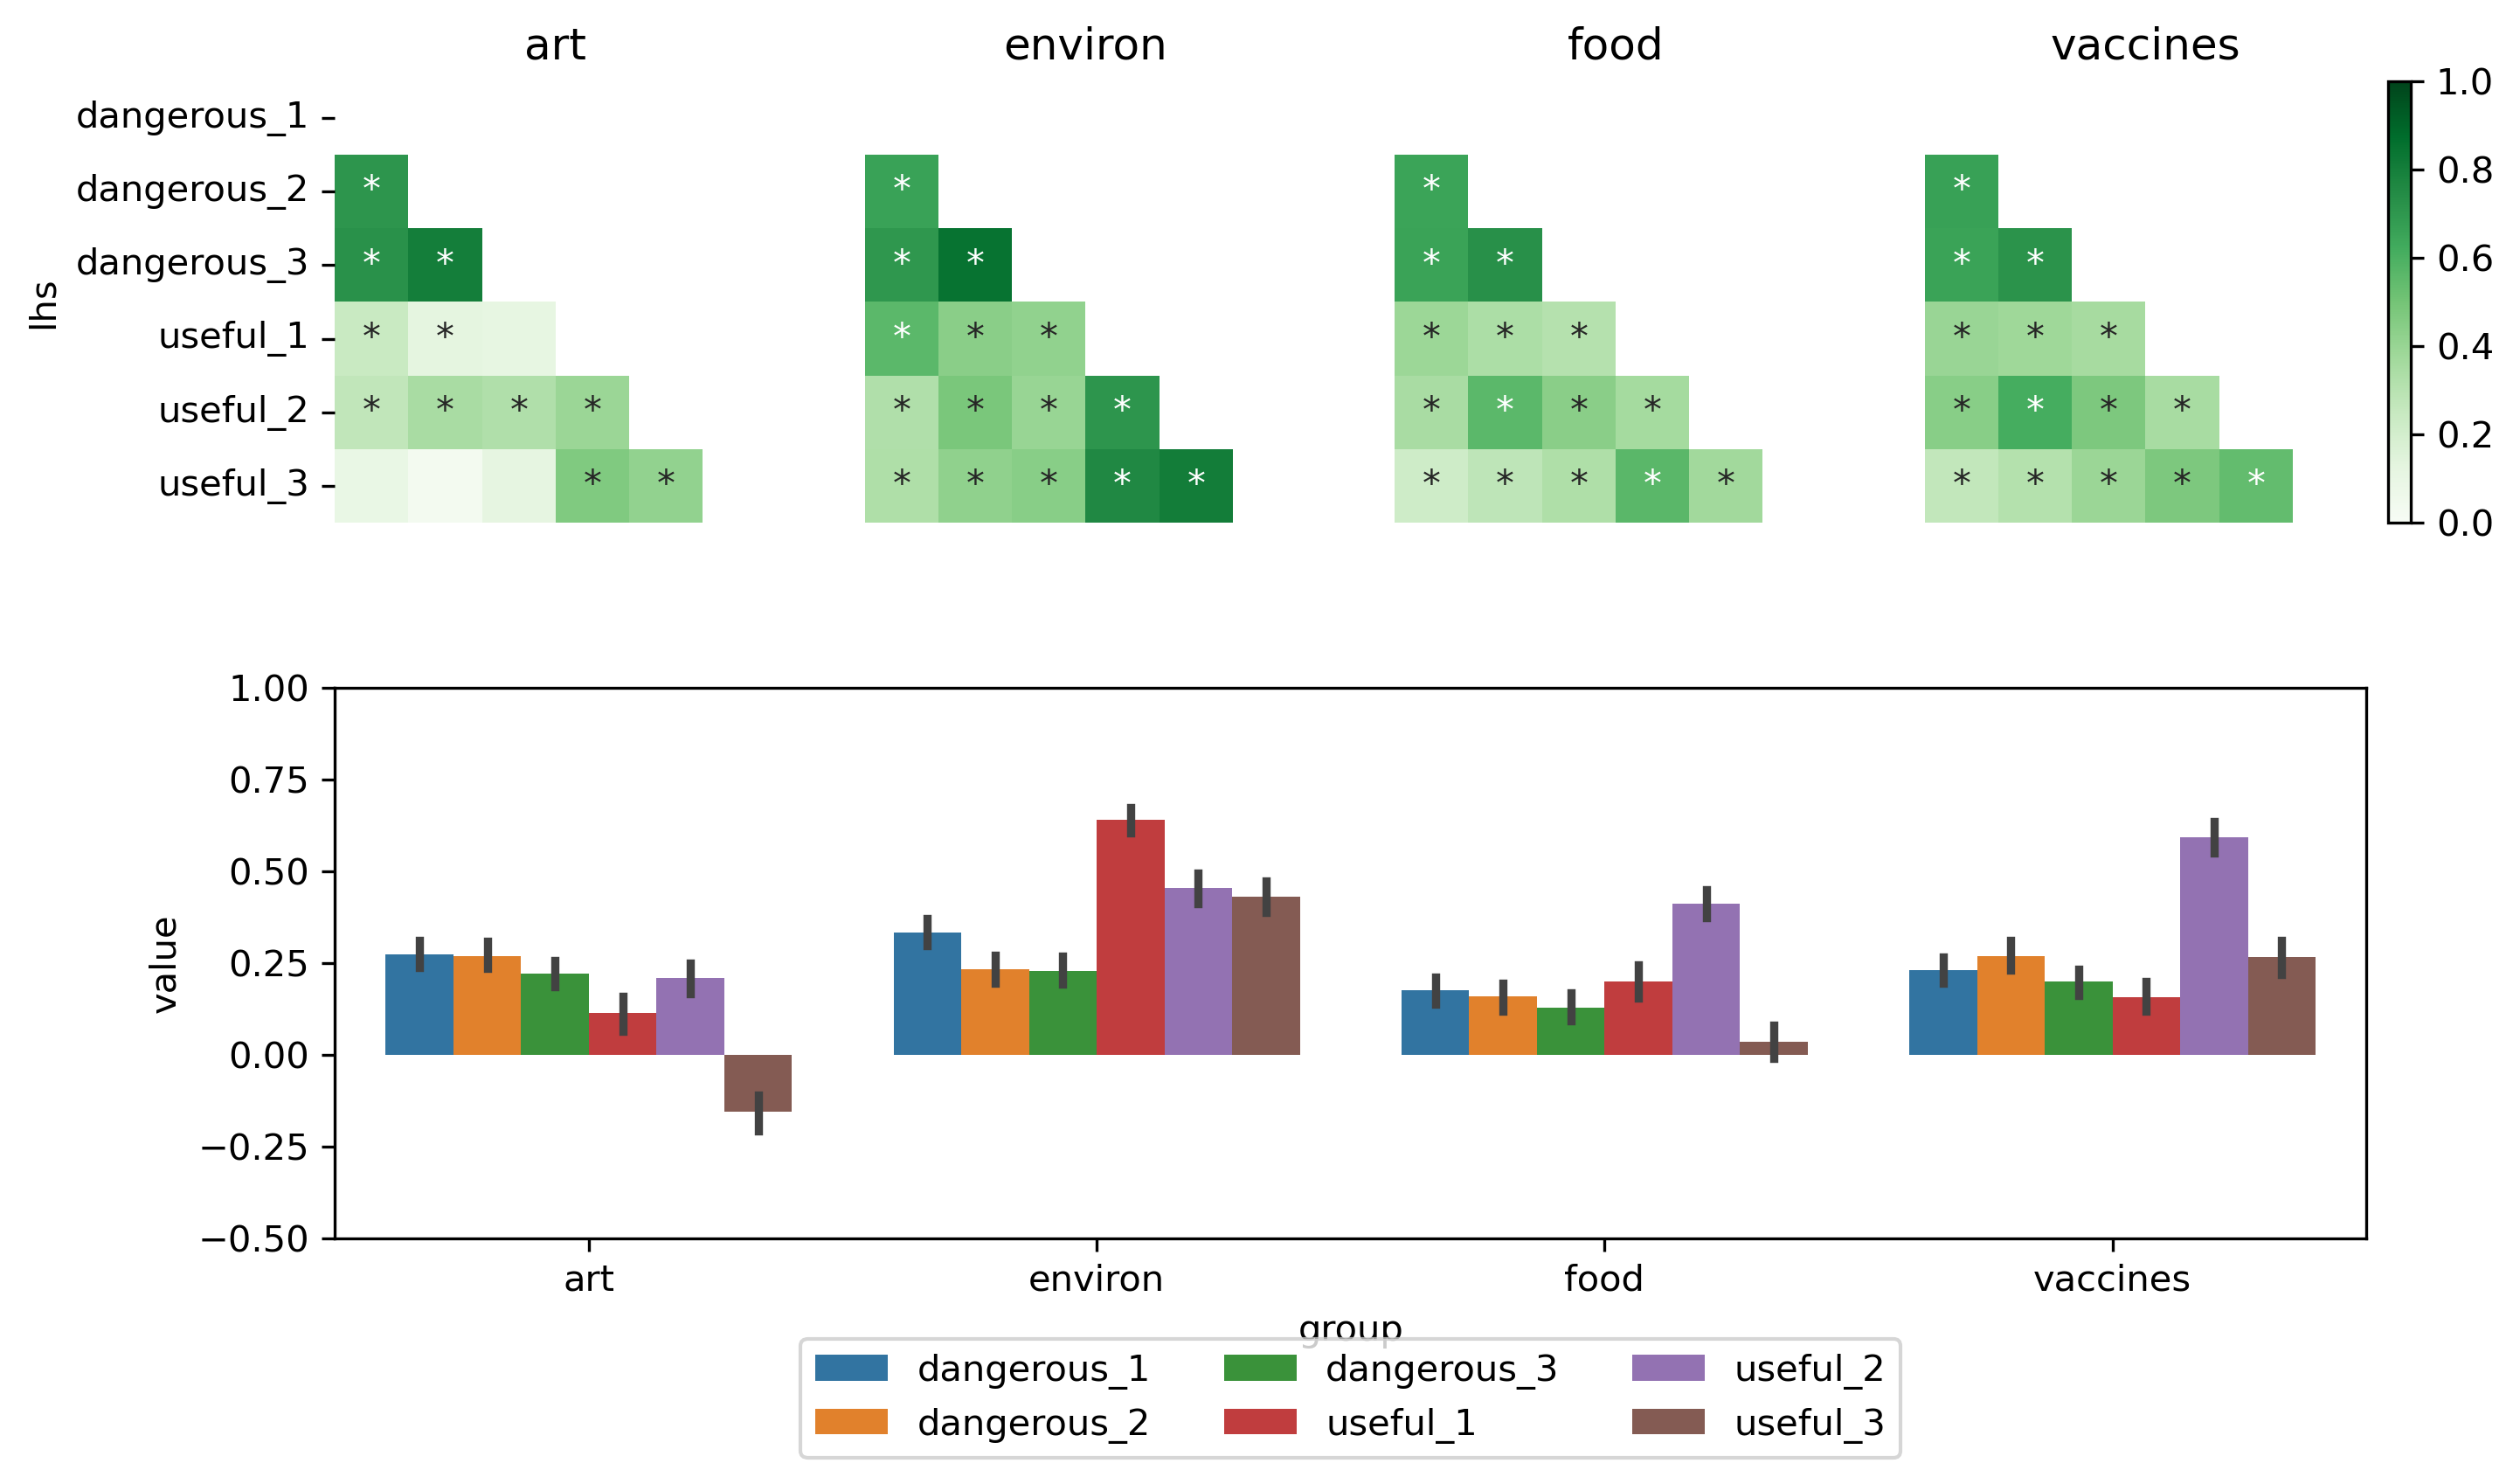

In [206]:
fig, axes = plt.subplot_mosaic("ABCD;EEEE", figsize=(10,6), dpi=300)
axes = list(axes.values())

corrs = {}

for i, g in enumerate(sorted(groups)):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='Estimate')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue').loc[table_e.index][table_e.index]
    table_e = table_e.rename(index={i: '_'.join(i.split('_')[1:]) for i in table_e.index})
    #upper_tri = 
    
    corrs[g] = table_e
    
    sns.heatmap(table_e, ax=axes[i], cmap='Greens', vmin=0, vmax=1,  fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], vmin=0, vmax=1, cmap="Greens")

QC_melt = QC.reset_index().melt(value_vars=all_questions, id_vars=['prolific_pid'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[-1], palette='tab10')
axes[-1].set_ylim([-0.5, 1])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

fig.savefig('../results/question_effects.svg')
fig.savefig('../results/question_effects.png')

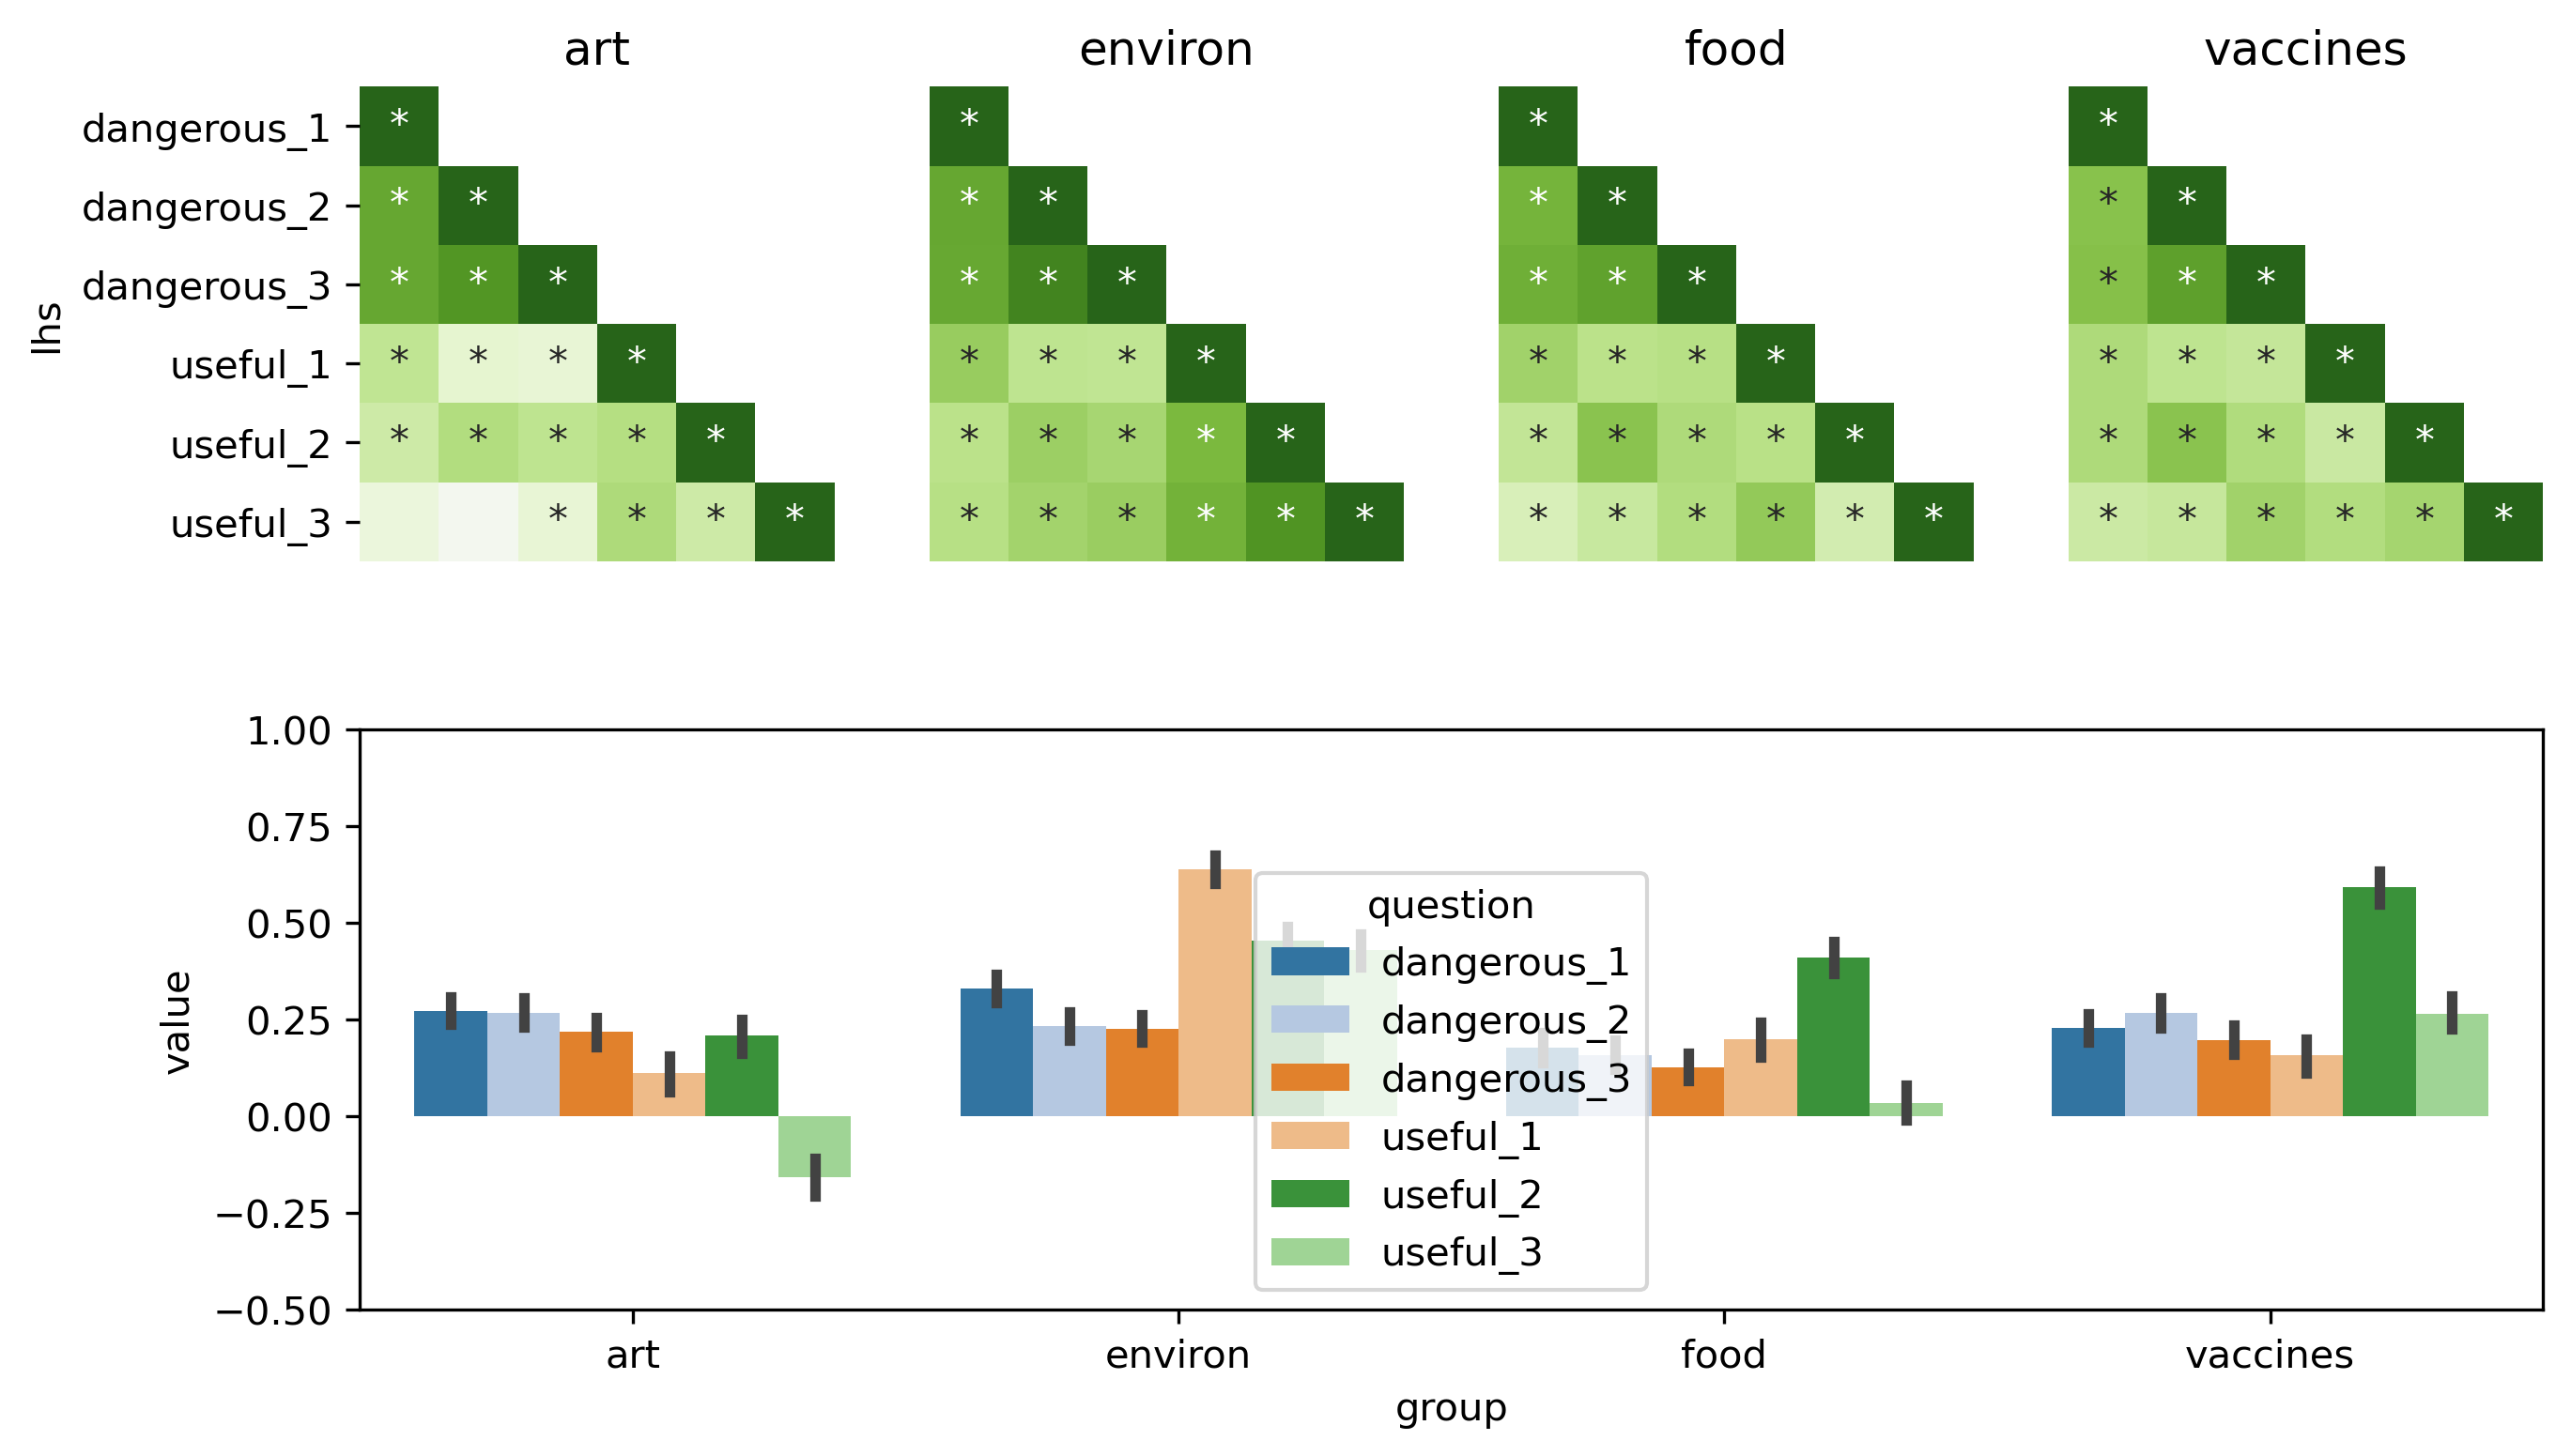

In [507]:
fig, axes = plt.subplot_mosaic("ABCD;EEEE", figsize=(10,6), dpi=300)
axes = list(axes.values())

corrs = {}

for i, g in enumerate(sorted(groups)):
    r = results[(results.lhs_group == g) & (results.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='p')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue').loc[table_e.index][table_e.index]
    table_e = table_e.rename(index={i: '_'.join(i.split('_')[1:]) for i in table_e.index})
    #upper_tri = 
    
    corrs[g] = table_e
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

QC_melt = QC.reset_index().melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[-1], palette='tab20')
axes[-1].set_ylim([-0.5, 1])

fig.savefig('../results/question_corr.svg')
fig.savefig('../results/question_corr.png')

### Additional analysis

##### for g in corrs:
    x = corrs[g].rename(columns={c : '_'.join(c.split('_')[1:]) for c in corrs[g].columns})
    y = x.values[np.tril_indices_from(x, -1)]
    
    print("%s, q-value=%f" % (g, scipy.stats.ranksums(y[:3], y[3:]).pvalue*4))
#efor

In [537]:
x

rhs,dangerous_1,dangerous_2,dangerous_3,useful_1,useful_2,useful_3
lhs,,,,,,
dangerous_1,1.000000,0.569568,0.571678,0.436776,0.435518,0.315968
dangerous_2,0.569568,1.000000,0.730150,0.367540,0.562272,0.340910
dangerous_3,0.571678,0.730150,1.000000,0.348904,0.424672,0.482964
useful_1,0.436776,0.367540,0.348904,1.000000,0.323063,0.419729
useful_2,0.435518,0.562272,0.424672,0.323063,1.000000,0.466247
useful_3,0.315968,0.340910,0.482964,0.419729,0.466247,1.000000


In [538]:
y

array([0.56956753, 0.57167756, 0.73014951, 0.43677613, 0.36753963,
       0.34890415, 0.43551808, 0.56227159, 0.42467202, 0.32306317,
       0.31596752, 0.34091032, 0.48296352, 0.41972867, 0.4662472 ])

### Intergroup questions

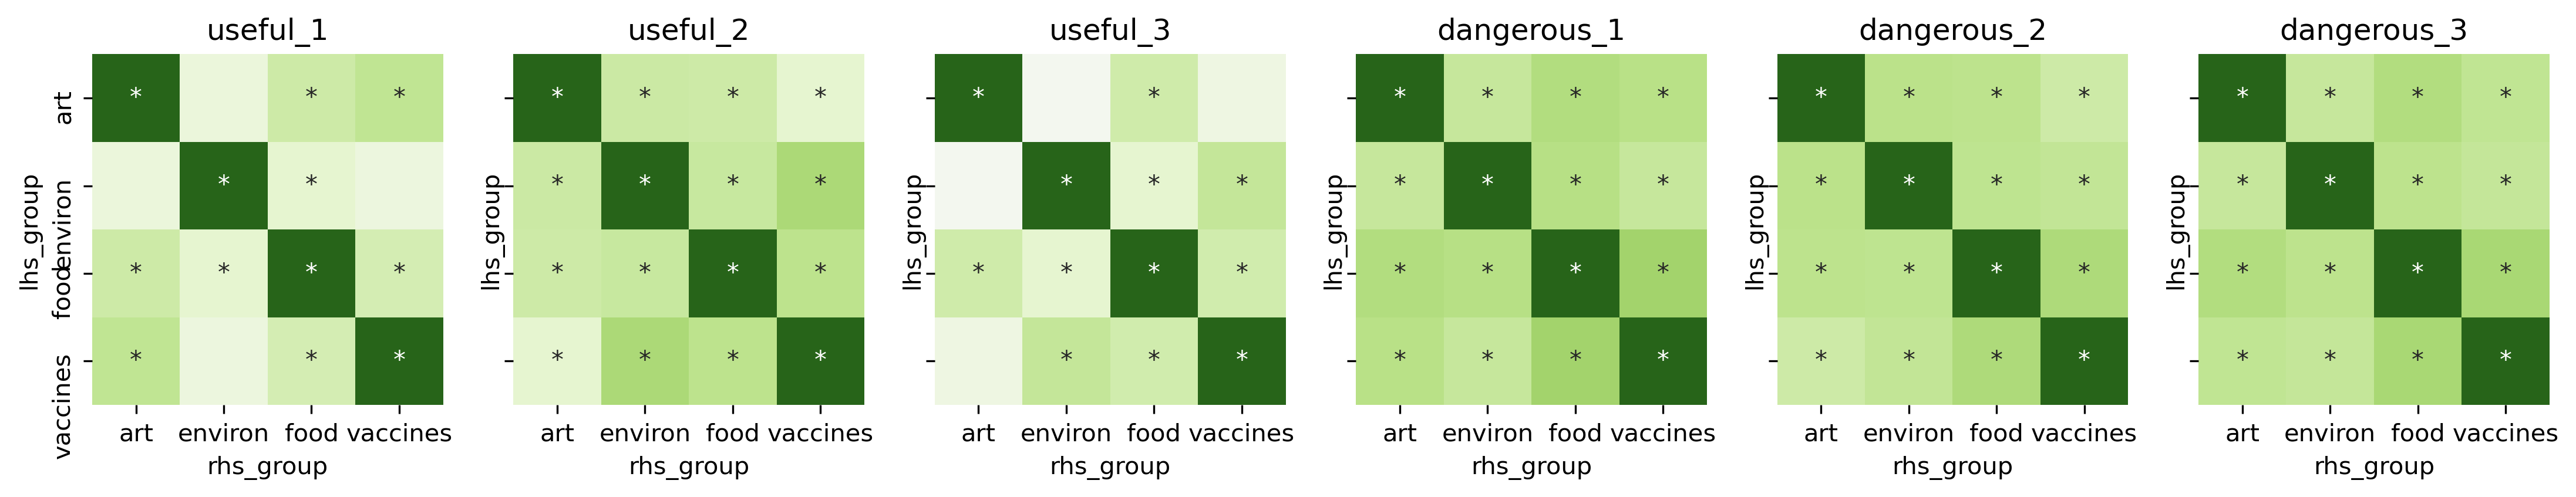

In [407]:
fig, axes = biu.utils.figure.subplots(figsize=(3*6,3), ncols=6, sharex=True, sharey=True)

for i, q in enumerate(sorted(group_questions)):
    r = results[(results.lhs_question == q) & (results.rhs_question == q)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates(['lhs','rhs'])
    
    table_e = r.pivot(index='lhs_group', columns='rhs_group', values='p')
    table_p = r.pivot(index='lhs_group', columns='rhs_group', values='qvalue')
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(q)
#efor

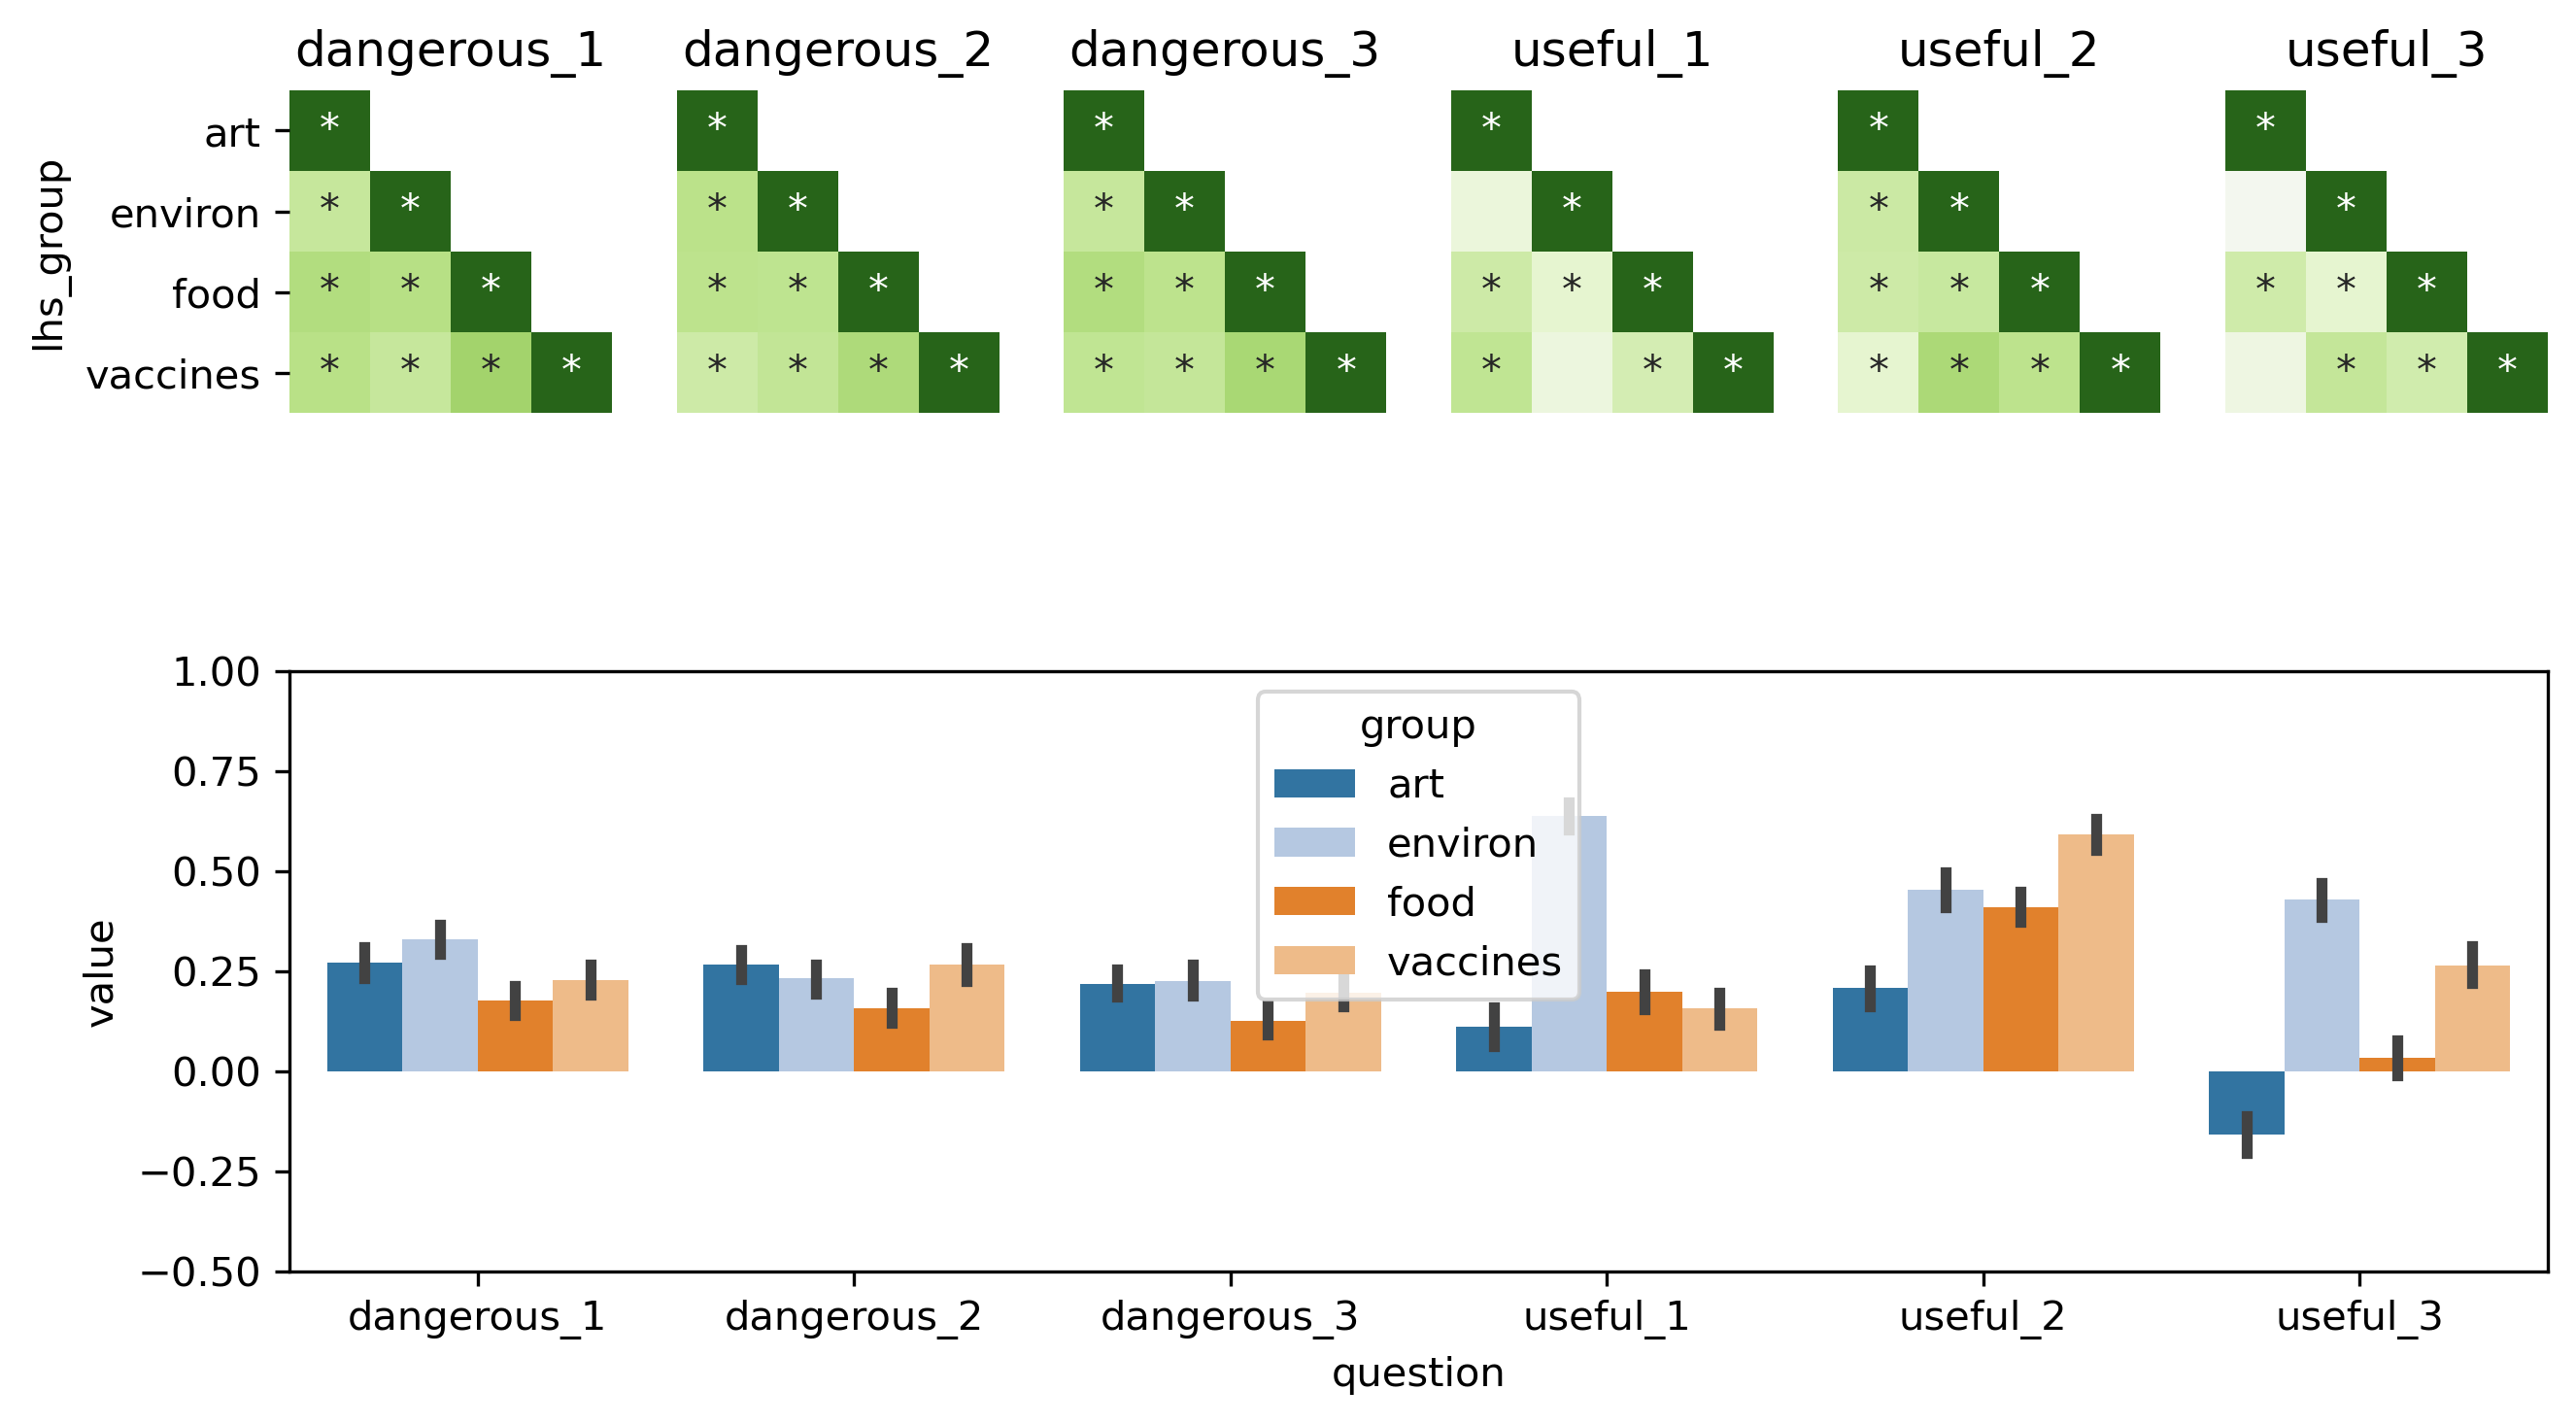

In [501]:
fig, axes = plt.subplot_mosaic("ABCDEF;GGGGGG", figsize=(10,6), dpi=300)
axes = list(axes.values())

#fig, axes = biu.utils.figure.subplots(figsize=(3*6,3), ncols=6, sharex=True, sharey=True)

for i, q in enumerate(sorted(group_questions)):
    r = results[(results.lhs_question == q) & (results.rhs_question == q)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    r = pd.concat([r, rprim]).drop_duplicates(['lhs','rhs'])
    
    table_e = r.pivot(index='lhs_group', columns='rhs_group', values='p')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs_group', columns='rhs_group', values='qvalue').loc[table_e.index][table_e.index]
    
    sns.heatmap(table_e, ax=axes[i], cmap='PiYG', vmin=-1, vmax=1, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(q)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

QC_melt = QC.reset_index().melt(value_vars=all_questions, id_vars=['index'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='question', y='value', hue='group', data=QC_melt, ax=axes[-1], palette='tab20')
axes[-1].set_ylim([-0.5, 1])

fig.savefig('../results/group_corr.svg')
fig.savefig('../results/group_corr.png')

(array([  4.,   0.,  14.,   0.,   0.,  46.,   0., 207.,   0., 225.]),
 array([-1. , -0.8, -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ]),
 <BarContainer object of 10 artists>)

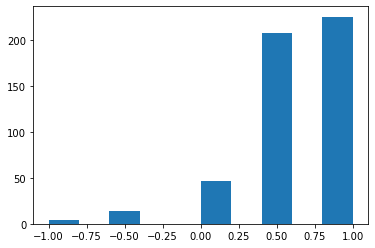

In [485]:
plt.hist(QC_melt[QC_melt.variable == "environ_useful_1"].value)

# Perform linear regression correlation analyses


In [185]:
res = []
for (X, Y), Z in formulas.items():

    if X == Y:
        continue
    #fi

    print("\r %s, %s            " % (X, Y), end="")

    data = QC[[X,Y]+Z]
    data = data.rename(columns={X:'X', Y:'Y'})
    
    
    data['participant'] = data.index
    
    formula = "Y ~ %s" % (' + '.join(["X"] + Z))
    
    R("""
    library(lmerTest)
    
    fit <- lm(as.formula(formula), data=data)
    
    coef <- as.data.frame(coefficients(summary(fit)))
    
    NULL
    """, push=dict(formula=formula, data=data.drop_duplicates('participant')))
    
    r = R("coef")
    r['lhs'] = X
    r['rhs'] = Y
    r['lhs_group'] = X.split('_')[0]
    r['rhs_group'] = Y.split('_')[0]
    r['lhs_question'] = '_'.join(X.split('_')[1:])
    r['rhs_question'] = '_'.join(Y.split('_')[1:])

    res.append(r.loc[['X']])

#efor

res = pd.concat(res).reset_index(drop=True)
res['qvalue'] = biu.stats.p_adjust(res['Pr(>|t|)'])

res_lc = res

 art_dangerous_2, art_dangerous_3                      

In [195]:
R("print(summary(fit));0")


Call:
lm(formula = as.formula(formula), data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.38771 -0.03368  0.01407  0.10146  1.01804 

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)    
(Intercept)              0.2003231  0.1761611   1.137 0.256055    
X                        0.8030845  0.0278242  28.863  < 2e-16 ***
art_knowledgeTRUE        0.0043381  0.0339685   0.128 0.898433    
age                      0.0013578  0.0008612   1.577 0.115580    
sexMale                 -0.0294229  0.0229191  -1.284 0.199857    
residenceAustria        -0.0631494  0.3044181  -0.207 0.835754    
residenceCanada         -0.2299335  0.1773317  -1.297 0.195399    
residenceChile          -0.2089177  0.3005210  -0.695 0.487285    
residenceFrance         -0.2979768  0.2464490  -1.209 0.227244    
residenceGermany        -0.6820920  0.2464957  -2.767 0.005879 ** 
residenceIreland        -0.1234531  0.1873983  -0.659 0.510366    
residenceItaly         

array([0.])

## Visualise

### Intragroup questions

/tmp/ipykernel_3628891/2329664388.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2329664388.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2329664388.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/2329664388.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


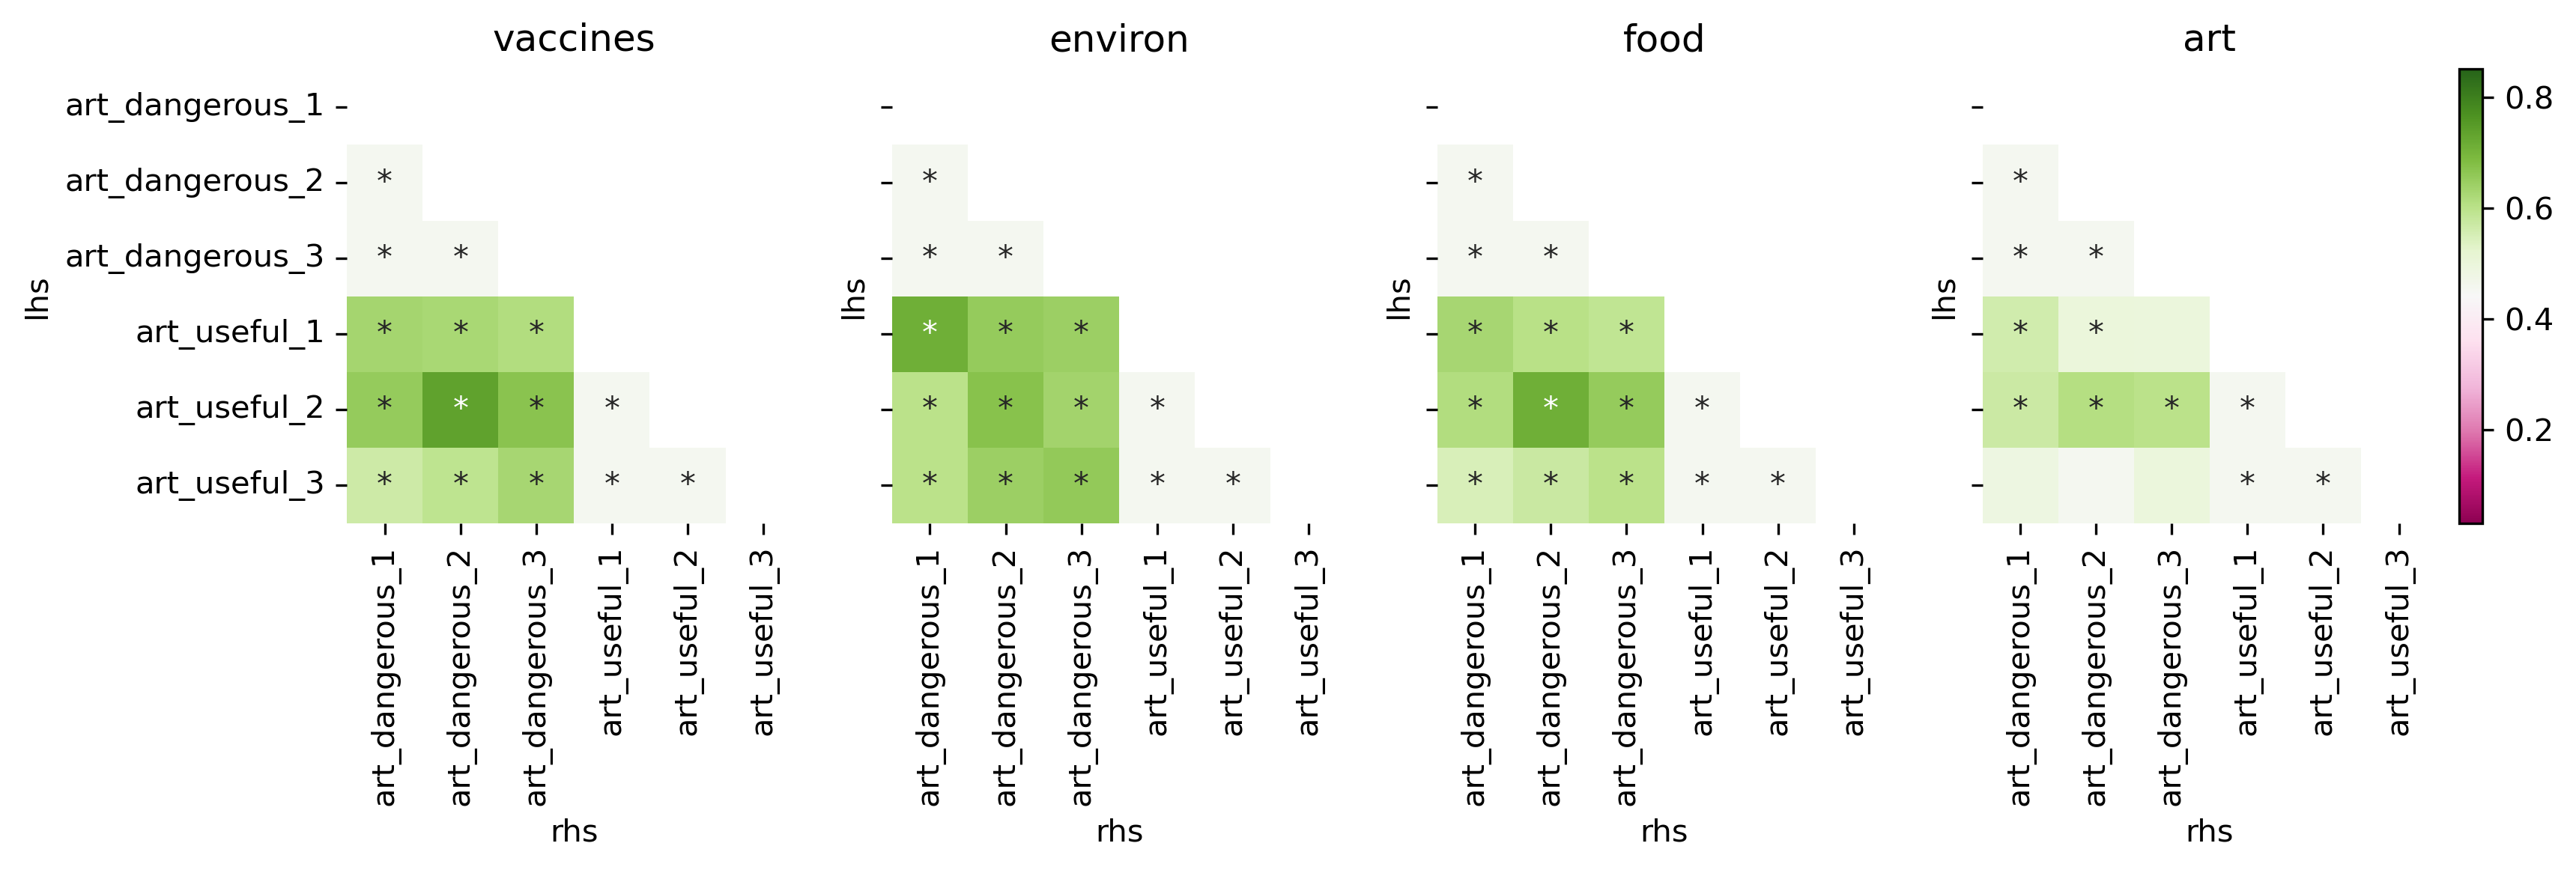

In [186]:
res = res_lc
fig, axes = biu.utils.figure.subplots(figsize=(12,3), ncols=4, sharex=True, sharey=True)

for i, g in enumerate(groups):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    rprim.Estimate = -rprim.Estimate
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = r.pivot(index='lhs', columns='rhs', values='Estimate')
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue')
    #upper_tri = 
    
    sns.heatmap(table_e, ax=axes[i], cmap='Greens', vmin=0, vmax=1, center=0, fmt='s',
                annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
#efor

move_colorbar(axes[-1], res.Estimate, cmap="PiYG")

/tmp/ipykernel_3628891/4258995197.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/4258995197.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/4258995197.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),
/tmp/ipykernel_3628891/4258995197.py:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot=(table_p < 0.05).applymap(lambda x: '*' if x else ''),


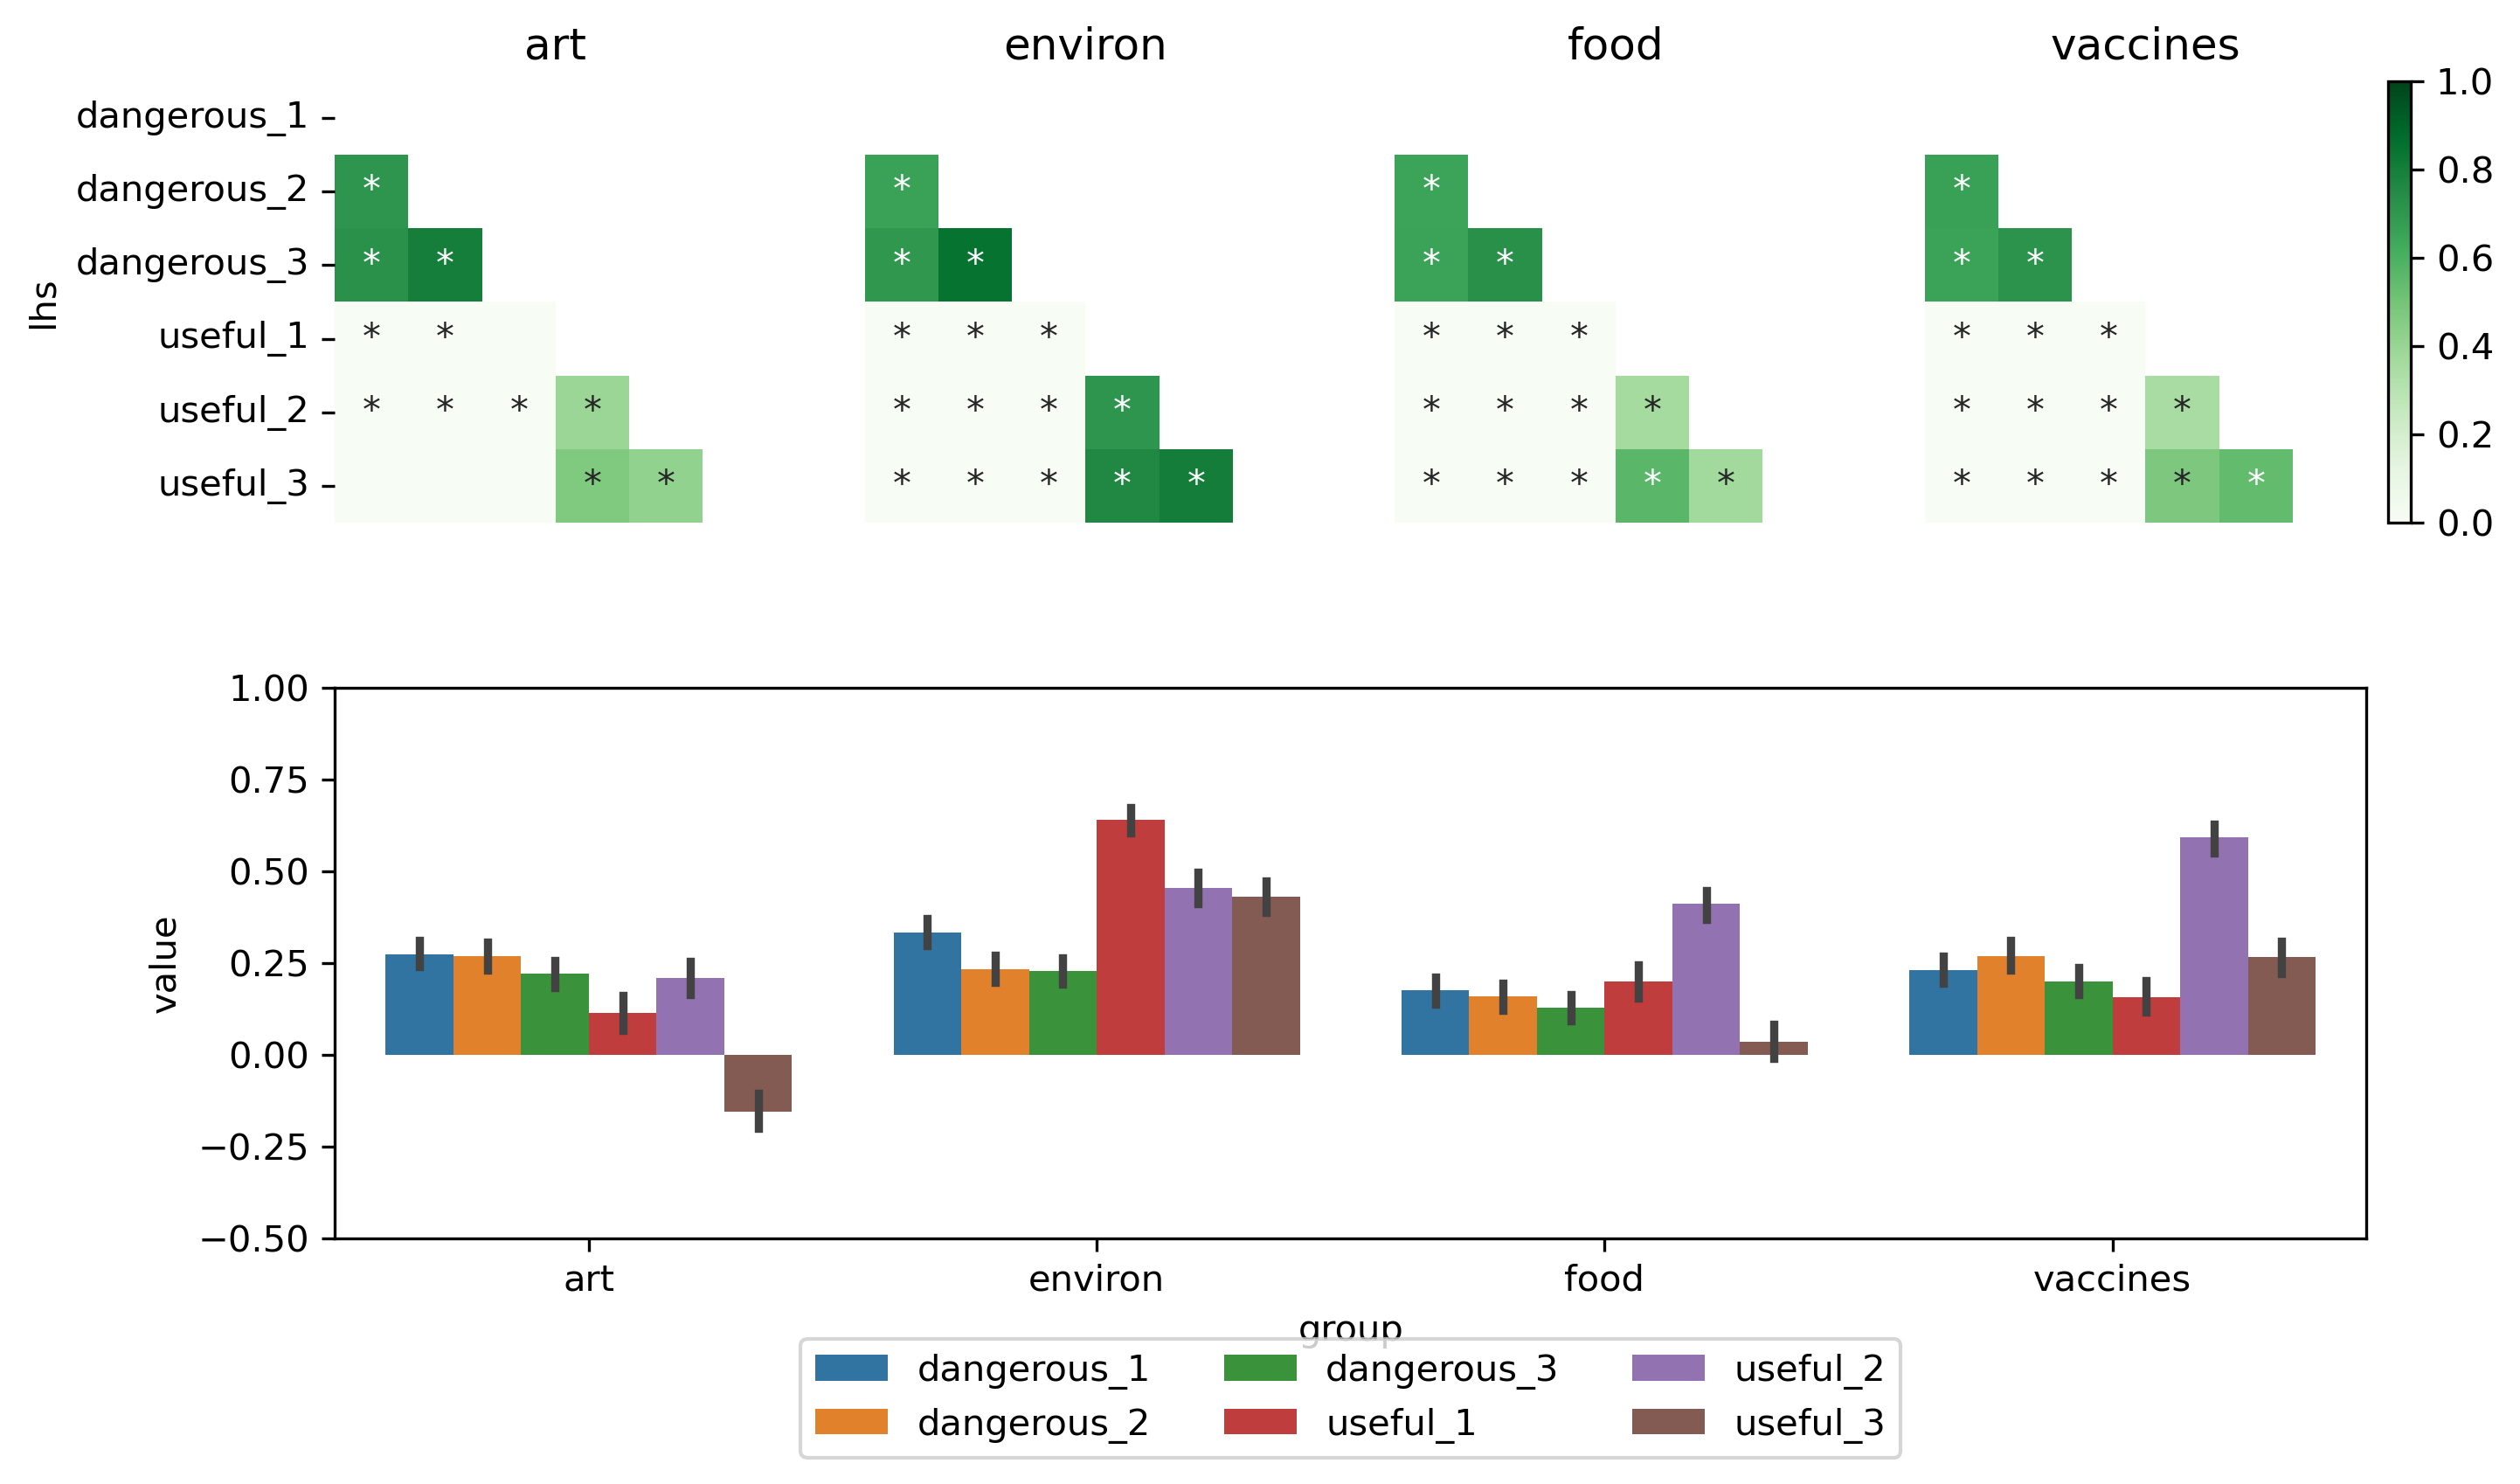

In [196]:
fig, axes = plt.subplot_mosaic("ABCD;EEEE", figsize=(10,6), dpi=300)
axes = list(axes.values())

corrs = {}

for i, g in enumerate(sorted(groups)):
    r = res[(res.lhs_group == g) & (res.rhs_group == g)]
    rprim = r.copy().rename(columns={'lhs':'rhs', 'rhs':'lhs',
                                     'lhs_group':'rhs_group', 'rhs_group':'lhs_group',
                                     'lhs_question':'rhs_question', 'rhs_question':'lhs_question'})
    rprim.Estimate = -rprim.Estimate # OMG how did I miss this??
    r = pd.concat([r, rprim]).drop_duplicates()
    
    table_e = -1*r.pivot(index='lhs', columns='rhs', values='Estimate')
    idx = sorted(table_e.index)
    table_e = table_e.loc[idx][idx]
    table_p = r.pivot(index='lhs', columns='rhs', values='qvalue').loc[table_e.index][table_e.index]
    table_e = table_e.rename(index={i: '_'.join(i.split('_')[1:]) for i in table_e.index})
    #upper_tri = 
    
    corrs[g] = table_e
    
    sns.heatmap(table_e, ax=axes[i], cmap='Greens', vmin=0, vmax=1, fmt='s',
                annot=(table_p < 0.05).map(lambda x: '*' if x else ''),
                mask=np.triu(np.ones((table_e.shape[0],table_e.shape[0])),1) == 1,
                cbar=False)
    axes[i].set(adjustable='box', aspect='equal')
    axes[i].set_title(g)
    axes[i].get_xaxis().set_visible(False)
    if i > 0:
        axes[i].sharey(axes[0])
        axes[i].get_yaxis().set_visible(False)
    #fi
#efor

move_colorbar(axes[i], vmax=1, vmin=0, cmap="Greens")

QC_melt = QC.reset_index().melt(value_vars=all_questions, id_vars=['prolific_pid'])
QC_melt['group'] = QC_melt.variable.apply(lambda x: x.split('_')[0])
QC_melt['question'] = QC_melt.variable.apply(lambda x: '_'.join(x.split('_')[1:]))
QC_melt = QC_melt.sort_values(['group','variable'])

sns.barplot(x='group', y='value', hue='question', data=QC_melt, ax=axes[-1], palette='tab10')
axes[-1].set_ylim([-0.5, 1])
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

fig.savefig('../results/question_effects.svg')
fig.savefig('../results/question_effects.png')